# Santorini AlphaZero (base game) — exact solver + self-play on GPU

**Pipeline**
1. C++ engine and df-pn solver, verified against an independent brute-force reference.
2. C++ AlphaZero layer: action encoding, D4 symmetries, input planes, threaded solver labelling, and a batched self-play MCTS. The MCTS uses forced-move pruning, MCTS-Solver proofs and an exact root solve late in the game.
3. JAX/Flax ResNet, bfloat16 on A100/L4/H100 and float32 on older GPUs such as the T4.
4. **Phase 0**: supervised warm start on solver-labelled late positions.
5. **Phase 1**: AlphaZero self-play; positions the solver proves get exact value targets.
6. Evaluation on a held-out solver test set and arena matches.

**Runtime:** *Runtime → Change runtime type → GPU*.

**Switching runtimes:** `Santorini_AlphaZero.ipynb` is the TPU version. Both save to the same Google Drive folder (`MyDrive/santorini_az`) with the same network, so either notebook resumes where the other stopped: datasets, phase-0 weights, the latest checkpoint and the replay buffer.

**Logging:** every line is stamped with the clock time and the minutes since the notebook started. Long steps print progress with rates and an ETA about every 15–30 seconds.

Conventions: cells `A1..E5`, row 1 on top. States are always from the side to move's perspective.

In [ ]:
import os, sys, subprocess, sysconfig, time, math, pickle, functools
import importlib.metadata as md
SMOKE = os.environ.get("SMOKE") == "1"          # tiny end-to-end test configuration
TARGET = "gpu"
T_START = time.time()

def log(msg=""):
    print(f"[{time.strftime('%H:%M:%S')} | {(time.time() - T_START) / 60:6.1f} min] {msg}", flush=True)

def fmt_time(sec):
    sec = max(0.0, float(sec))
    return f"{sec:.0f}s" if sec < 90 else f"{sec / 60:.1f} min" if sec < 5400 else f"{sec / 3600:.1f} h"

class Every:
    # True at most once every `seconds` (rate-limits progress lines).
    def __init__(self, seconds):
        self.s, self.t = seconds, time.time()
    def __call__(self):
        if time.time() - self.t >= self.s:
            self.t = time.time()
            return True
        return False

# Colab's preinstalled Flax can lag behind its JAX (e.g. "jax.core.get_opaque_trace_state was
# removed"). Upgrade Flax/optax while pinning the installed JAX and its GPU plugins so the
# accelerator build of JAX is never replaced.
installed = {d.metadata["Name"].lower() for d in md.distributions()}
flax_before = md.version("flax") if "flax" in installed else None
pins = [f"{p}=={md.version(p)}" for p in ("jax", "jaxlib", "libtpu", "libtpu-nightly", "jax-cuda12-plugin",
        "jax-cuda12-pjrt", "jax-cuda13-plugin", "jax-cuda13-pjrt") if p in installed]
open("constraints.txt", "w").write("\n".join(pins) + "\n")
log(f"installing pybind11 and upgrading flax/optax (flax before: {flax_before}), pinned: {', '.join(pins)}")
t = time.time()
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "pybind11", "flax", "optax",
                "-c", "constraints.txt"], check=True)
flax_after = md.version("flax")
log(f"pip done in {fmt_time(time.time() - t)}: flax {flax_after}, optax {md.version('optax')}")
if "flax" in sys.modules and flax_before != flax_after:
    raise SystemExit(f"Flax was upgraded {flax_before} -> {flax_after} after it was already imported. "
                     "Restart the session (Runtime -> Restart session) and run all cells again.")
import numpy as np
import jax
backend = jax.default_backend()
log(f"JAX {jax.__version__} | backend {backend} | {jax.device_count()} device(s): {jax.devices()[0].device_kind} "
    f"| host CPUs {os.cpu_count()} | SMOKE {SMOKE}")
if backend != "gpu" and not SMOKE:
    log("WARNING: no GPU found. Use Runtime -> Change runtime type -> GPU"
        " (or the TPU notebook). Continuing on " + backend + ".")

[14:22:45 |    0.0 min] installing pybind11 and upgrading flax/optax (flax before: 0.11.2), pinned: jax==0.11.1, jaxlib==0.11.1
[14:22:50 |    0.1 min] pip done in 4s: flax 0.12.12, optax 0.2.9
[14:22:50 |    0.1 min] JAX 0.11.1 | backend cpu | 1 device(s): cpu | host CPUs 2 | SMOKE False
[14:22:50 |    0.1 min] WARNING: no GPU found. Use Runtime -> Change runtime type -> GPU (or the TPU notebook). Continuing on cpu.


## 1. C++ engine, solver and AlphaZero layer
The sources below are written to the runtime's working directory.

### `engine.h` — bitboards, move generation, forced-move pruning, symmetry hashing

In [ ]:
%%writefile engine.h
// Santorini (base game, no god powers) engine: bitboards, move generation,
// forced-move pruning, D4 symmetry and canonical Zobrist keys.
//
// Board: 25 cells, index = row*5 + col, row 0 = top (row "1"), col 0 = "A".
// Positions are stored from the side-to-move's perspective: `me` moves next.
#pragma once
#include <cstdint>
#include <cstdio>
#include <cstring>
#include <string>
#include <random>
#include <algorithm>

typedef uint32_t BB;
constexpr BB FULL = (1u << 25) - 1;
inline int lsb(BB b) { return __builtin_ctz(b); }
inline int pc(BB b) { return __builtin_popcount(b); }
inline BB bit(int c) { return 1u << c; }

// Official piece supply: 22 level-1, 18 level-2, 14 level-3 blocks, 18 domes.
constexpr int LIMIT1 = 22, LIMIT2 = 18, LIMIT3 = 14, LIMITD = 18;

struct Tables {
    BB adj[25];
    uint8_t sym[8][25];          // D4 symmetry: sym[s][cell] -> image cell
    uint64_t zh[25][5];          // height keys (zh[c][0] = 0)
    uint64_t zme[25], zop[25];   // worker keys (mover / opponent)
};
inline Tables T;

inline void initTables() {
    for (int c = 0; c < 25; c++) {
        int r = c / 5, k = c % 5;
        BB m = 0;
        for (int dr = -1; dr <= 1; dr++)
            for (int dk = -1; dk <= 1; dk++) {
                if (!dr && !dk) continue;
                int rr = r + dr, kk = k + dk;
                if (rr >= 0 && rr < 5 && kk >= 0 && kk < 5) m |= bit(rr * 5 + kk);
            }
        T.adj[c] = m;
        for (int s = 0; s < 8; s++) {
            int x = k, y = r;              // rotate s&3 times, then mirror if s>=4
            for (int i = 0; i < (s & 3); i++) { int nx = 4 - y, ny = x; x = nx; y = ny; }
            if (s >= 4) x = 4 - x;
            T.sym[s][c] = (uint8_t)(y * 5 + x);
        }
    }
    std::mt19937_64 rng(0x5a170421ULL);
    for (int c = 0; c < 25; c++) {
        T.zh[c][0] = 0;
        for (int h = 1; h < 5; h++) T.zh[c][h] = rng();
        T.zme[c] = rng();
        T.zop[c] = rng();
    }
}

struct Pos {
    BB h1 = 0, h2 = 0, h3 = 0, dm = 0;  // height >=1, >=2, >=3, dome
    BB me = 0, op = 0;                  // worker sets

    int height(int c) const {
        return ((h1 >> c) & 1) + ((h2 >> c) & 1) + ((h3 >> c) & 1) + ((dm >> c) & 1);
    }
    BB lvl(int l) const {
        switch (l) {
            case 0: return FULL & ~h1;
            case 1: return h1 & ~h2;
            case 2: return h2 & ~h3;
            case 3: return h3 & ~dm;
            default: return dm;
        }
    }
    int blocks() const { return pc(h1) + pc(h2) + pc(h3) + pc(dm); }
    void raise(int c) {
        BB b = bit(c);
        if (!(h1 & b)) h1 |= b;
        else if (!(h2 & b)) h2 |= b;
        else if (!(h3 & b)) h3 |= b;
        else dm |= b;
    }
    // Squares on which a block can currently be placed (supply limits respected).
    BB buildable() const {
        BB m = 0;
        if (pc(h1) < LIMIT1) m |= lvl(0);
        if (pc(h2) < LIMIT2) m |= lvl(1);
        if (pc(h3) < LIMIT3) m |= lvl(2);
        if (pc(dm) < LIMITD) m |= lvl(3);
        return m;
    }
};

struct Move { uint8_t f, t, b; };

// Squares a worker standing at height `lw` may step to (ignoring occupancy).
inline BB climbMask(const Pos& p, int lw) {
    if (lw == 0) return ~p.h2 & ~p.dm & FULL;
    if (lw == 1) return ~p.h3 & ~p.dm & FULL;
    return ~p.dm & FULL;
}

// Can the side owning `w` win right now by stepping from level 2 onto level 3?
inline bool canWinNow(const Pos& p, BB w) {
    BB occ = p.me | p.op, L2 = p.lvl(2), L3 = p.lvl(3);
    for (BB x = w & L2; x; x &= x - 1)
        if (T.adj[lsb(x)] & L3 & ~occ) return true;
    return false;
}

// Result of move generation with forced-move pruning.
//   win  : mover can win immediately (no need to look at moves)
//   n == 0 (and !win): mover is lost (no legal move, or every move hands the
//          opponent an immediate win)
// Otherwise m[0..n) are exactly the moves that do NOT let the opponent win
// on the very next step. Dropping the others is value-preserving: such a move
// loses, so the mover only needs them if nothing else exists (then: loss).
struct Gen {
    bool win;
    int n;
    Move m[128];
};

inline void genSafe(const Pos& p, Gen& g) {
    g.win = false;
    g.n = 0;
    if (canWinNow(p, p.me)) { g.win = true; return; }
    BB occ = p.me | p.op;
    BB L2 = p.lvl(2), L3 = p.lvl(3);
    BB oppAdj = 0;  // squares adjacent to an opponent worker standing on level 2
    for (BB x = p.op & L2; x; x &= x - 1) oppAdj |= T.adj[lsb(x)];
    BB danger2 = L2 & oppAdj;       // raising these to level 3 hands over a win
    BB bmAllowed = p.buildable();
    for (BB ws = p.me; ws; ws &= ws - 1) {
        int w = lsb(ws);
        BB dests = T.adj[w] & ~occ & climbMask(p, p.height(w));
        for (; dests; dests &= dests - 1) {
            int t = lsb(dests);
            BB occ2 = occ ^ bit(w) ^ bit(t);
            BB bm = T.adj[t] & ~occ2 & bmAllowed;
            BB threats = oppAdj & L3 & ~occ2;   // open level-3 squares the opponent can step onto
            BB safe;
            if (!threats) safe = bm & ~danger2;
            else if (!(threats & (threats - 1))) safe = bm & threats;  // must dome the single threat
            else safe = 0;                                              // two threats: cannot stop both
            for (; safe; safe &= safe - 1)
                g.m[g.n++] = Move{(uint8_t)w, (uint8_t)t, (uint8_t)lsb(safe)};
        }
    }
}

// Apply a move and flip perspective (opponent becomes the mover).
inline Pos makeChild(const Pos& p, Move m) {
    Pos c = p;
    c.raise(m.b);
    BB me2 = p.me ^ bit(m.f) ^ bit(m.t);
    c.me = p.op;
    c.op = me2;
    return c;
}

// ---- Symmetry-aware hashing ------------------------------------------------
// A Node carries the height hash under each of the 8 symmetries so a child's
// canonical key costs ~16 table lookups instead of re-hashing the board.
struct Node {
    Pos p;
    uint64_t hb[8];
};

inline Node makeRoot(const Pos& p) {
    Node n;
    n.p = p;
    for (int s = 0; s < 8; s++) {
        uint64_t h = 0;
        for (int c = 0; c < 25; c++) h ^= T.zh[T.sym[s][c]][p.height(c)];
        n.hb[s] = h;
    }
    return n;
}

inline uint64_t workersKey(int s, BB me, BB op) {
    uint64_t k = 0;
    for (BB x = me; x; x &= x - 1) k ^= T.zme[T.sym[s][lsb(x)]];
    for (BB x = op; x; x &= x - 1) k ^= T.zop[T.sym[s][lsb(x)]];
    return k;
}

inline uint64_t canonicalKey(const Node& n) {
    uint64_t best = ~0ULL;
    for (int s = 0; s < 8; s++) best = std::min(best, n.hb[s] ^ workersKey(s, n.p.me, n.p.op));
    return best;
}

inline Node childNode(const Node& n, Move m) {
    Node c;
    c.p = makeChild(n.p, m);
    int h0 = n.p.height(m.b);
    for (int s = 0; s < 8; s++) {
        int img = T.sym[s][m.b];
        c.hb[s] = n.hb[s] ^ T.zh[img][h0] ^ T.zh[img][h0 + 1];
    }
    return c;
}

// Fast canonical key of a child without building the full Node.
struct KeyCtx {
    uint64_t hb[8], meAsOp[8];  // child's opponent = parent's mover (moved worker added per move)
    uint64_t opAsMe[8];         // child's mover = parent's opponent (unchanged)
    void init(const Node& n) {
        for (int s = 0; s < 8; s++) {
            hb[s] = n.hb[s];
            opAsMe[s] = 0;
            for (BB x = n.p.op; x; x &= x - 1) opAsMe[s] ^= T.zme[T.sym[s][lsb(x)]];
        }
    }
    uint64_t childKey(const Node& n, Move m) const {
        int h0 = n.p.height(m.b);
        int other = lsb(n.p.me ^ bit(m.f));
        uint64_t best = ~0ULL;
        for (int s = 0; s < 8; s++) {
            const uint8_t* S = T.sym[s];
            uint64_t k = hb[s] ^ T.zh[S[m.b]][h0] ^ T.zh[S[m.b]][h0 + 1] ^ opAsMe[s] ^
                         T.zop[S[m.t]] ^ T.zop[S[other]];
            best = std::min(best, k);
        }
        return best;
    }
};

// ---- I/O helpers -------------------------------------------------------------
inline std::string sq(int c) {
    std::string s;
    s += char('A' + c % 5);
    s += char('1' + c / 5);
    return s;
}
inline int parseSq(const std::string& s) {
    return (s[1] - '1') * 5 + (toupper(s[0]) - 'A');
}
inline std::string moveStr(Move m) { return sq(m.f) + "-" + sq(m.t) + " build " + sq(m.b); }

// heights: 25 digits, row 1 (top) first. me/op: "D3,C5".
inline Pos parsePos(const std::string& heights, const std::string& me, const std::string& op) {
    Pos p;
    for (int c = 0; c < 25; c++)
        for (int i = 0; i < heights[c] - '0'; i++) p.raise(c);
    auto workers = [](const std::string& s) {
        BB b = 0;
        b |= bit(parseSq(s.substr(0, 2)));
        b |= bit(parseSq(s.substr(3, 2)));
        return b;
    };
    p.me = workers(me);
    p.op = workers(op);
    return p;
}

inline void printPos(const Pos& p, const char* meName = "X", const char* opName = "O") {
    printf("     A   B   C   D   E\n");
    for (int r = 0; r < 5; r++) {
        printf("  %d ", r + 1);
        for (int k = 0; k < 5; k++) {
            int c = r * 5 + k, h = p.height(c);
            char w = (p.me >> c & 1) ? meName[0] : (p.op >> c & 1) ? opName[0] : ' ';
            if (h == 4) printf(" [] ");
            else printf(" %d%c ", h, w);
        }
        printf("\n");
    }
    printf("  (%c = side to move, %c = opponent, [] = dome)\n", meName[0], opName[0]);
}

Writing engine.h


### `solver.h` — transposition table, df-pn search, training labels

In [ ]:
%%writefile solver.h
// Transposition table + depth-first proof-number search (df-pn) with the
// 1+epsilon threshold trick. Values are from the side-to-move's perspective:
//   pn == 0  -> mover wins (proven)      dn == 0 -> mover loses (proven)
// Santorini's game graph is a DAG (every turn adds a block), so there is no
// repetition / graph-history-interaction problem for df-pn.
#pragma once
#include "engine.h"
#include <atomic>
#include <chrono>
#include <cmath>
#include <vector>

constexpr uint32_t INF = 0x3FFFFFFF;
inline uint32_t sat(uint64_t x) { return x >= INF ? INF : (uint32_t)x; }

// ---- Transposition table -------------------------------------------------------
// 4-way buckets of 16-byte entries (one cache line). The 48-bit tag plus the
// bucket index together verify all 64 key bits. Replacement keeps the entries
// that cost the most work to compute; proven results get a large bonus.
struct TT {
    struct Entry {
        uint64_t tagWork;  // high 48 bits: key tag, low 16 bits: log2(work) * 1024
        uint32_t pn, dn;
    };
    Entry* t = nullptr;
    uint64_t nBuckets = 0, mask = 0;
    uint64_t stores = 0, used = 0;

    void alloc(double gb) {
        uint64_t bytes = (uint64_t)(gb * (1ULL << 30));
        nBuckets = 1;
        while (nBuckets * 2 * 64 <= bytes) nBuckets *= 2;
        mask = nBuckets - 1;
        t = (Entry*)aligned_alloc(64, nBuckets * 64);
        memset(t, 0, nBuckets * 64);
    }
    static uint64_t tagOf(uint64_t key) { return key & ~0xFFFFULL; }
    Entry* bucket(uint64_t key) { return t + (key & mask) * 4; }

    bool lookup(uint64_t key, uint32_t& pn, uint32_t& dn) {
        Entry* b = bucket(key);
        uint64_t tag = tagOf(key);
        for (int i = 0; i < 4; i++)
            if ((b[i].tagWork & ~0xFFFFULL) == tag && (b[i].pn | b[i].dn)) {
                pn = b[i].pn;
                dn = b[i].dn;
                return true;
            }
        return false;
    }
    static uint32_t prio(const Entry& e) {
        uint32_t w = e.tagWork & 0xFFFF;
        if (e.pn == 0 || e.dn == 0) w += 40000;  // keep proofs
        return w;
    }
    void store(uint64_t key, uint32_t pn, uint32_t dn, uint64_t work) {
        stores++;
        Entry* b = bucket(key);
        uint64_t tag = tagOf(key);
        uint32_t w16 = std::min<uint32_t>(0xFFFF, (uint32_t)(std::log2((double)work + 1) * 1024));
        Entry* victim = nullptr;
        for (int i = 0; i < 4; i++)
            if ((b[i].tagWork & ~0xFFFFULL) == tag && (b[i].pn | b[i].dn)) { victim = &b[i]; break; }
        if (!victim) {
            for (int i = 0; i < 4; i++)
                if (!(b[i].pn | b[i].dn)) { victim = &b[i]; used++; break; }
        }
        if (!victim) {
            victim = &b[0];
            for (int i = 1; i < 4; i++)
                if (prio(b[i]) < prio(*victim)) victim = &b[i];
        }
        victim->tagWork = tag | w16;
        victim->pn = pn;
        victim->dn = dn;
    }
    double fill() const { return (double)used / (nBuckets * 4); }
};

// ---- df-pn -------------------------------------------------------------------
struct Solver {
    TT tt;
    double eps = 0.25;
    uint64_t expansions = 0;
    uint64_t nextReport = 1ULL << 22;
    std::chrono::steady_clock::time_point start, deadline;
    bool aborted = false;
    bool verbose = true;
    uint64_t budget = 0;       // max expansions per solve() call; 0 = unlimited
    uint64_t budgetStart = 0;

    double elapsed() const {
        return std::chrono::duration<double>(std::chrono::steady_clock::now() - start).count();
    }

    // Initial (pn, dn) for an unexplored child. Plain 1/1; children whose mover
    // is under an immediate threat get a smaller disproof estimate because
    // their reply is forced.
    int heuristic = 1;
    void initChild(const Pos& c, uint32_t& pn, uint32_t& dn) {
        pn = 1;
        dn = 1;
        if (!heuristic) return;
        // Threats the child's mover must answer (open level-3 squares next to an
        // opposing worker on level 2).
        BB occ = c.me | c.op, L2 = c.lvl(2), L3 = c.lvl(3);
        BB adj = 0;
        for (BB x = c.op & L2; x; x &= x - 1) adj |= T.adj[lsb(x)];
        int threats = pc(adj & L3 & ~occ);
        if (threats >= 2) { pn = 4; dn = 1; return; }
        if (threats == 1) { pn = 2; dn = 1; return; }
        int d = 0;
        for (BB x = c.me; x; x &= x - 1) d += c.height(lsb(x));
        for (BB x = c.op; x; x &= x - 1) d -= c.height(lsb(x));
        if (d > 0) { pn = 1; dn = 1 + std::min(d, 3); }
        else if (d < 0) { pn = 1 + std::min(-d, 3); dn = 1; }
    }

    uint64_t mid(const Node& n, uint64_t key, uint32_t thpn, uint32_t thdn, uint32_t& outPn,
                 uint32_t& outDn) {
        expansions++;
        if (budget && expansions - budgetStart >= budget) aborted = true;  // per-position cap
        if (expansions >= nextReport) {
            nextReport += 1ULL << 22;
            if (verbose)
                fprintf(stderr, "  [%.0fs] %llu expansions, %.1f M/s, TT fill %.1f%%\n", elapsed(),
                        (unsigned long long)expansions, expansions / elapsed() / 1e6,
                        100 * tt.fill());
            if (std::chrono::steady_clock::now() > deadline) aborted = true;
        }
        Gen g;
        genSafe(n.p, g);
        if (g.win) { outPn = 0; outDn = INF; tt.store(key, 0, INF, 1); return 1; }
        if (g.n == 0) { outPn = INF; outDn = 0; tt.store(key, INF, 0, 1); return 1; }

        KeyCtx kc;
        kc.init(n);
        uint64_t ck[128];
        uint32_t cpn[128], cdn[128];
        for (int i = 0; i < g.n; i++) {
            ck[i] = kc.childKey(n, g.m[i]);
            if (!tt.lookup(ck[i], cpn[i], cdn[i])) initChild(makeChild(n.p, g.m[i]), cpn[i], cdn[i]);
        }
        uint64_t work = 1;
        uint32_t pn, dn;
        for (;;) {
            // pn(node) = min over children of dn(child); dn(node) = sum of pn(child)
            uint32_t best = INF + 1, second = INF;
            int bi = -1;
            uint64_t sum = 0;
            for (int i = 0; i < g.n; i++) {
                sum += cpn[i];
                if (cdn[i] < best) { second = best; best = cdn[i]; bi = i; }
                else if (cdn[i] < second) second = cdn[i];
            }
            pn = best;
            dn = sat(sum);
            if (second > INF) second = INF;
            if (pn >= thpn || dn >= thdn || aborted) break;
            uint32_t cthpn = sat((uint64_t)thdn - dn + cpn[bi]);
            uint64_t widened = std::max<uint64_t>((uint64_t)second + 1,
                                                  (uint64_t)std::ceil(second * (1.0 + eps)));
            uint32_t cthdn = (uint32_t)std::min<uint64_t>(thpn, widened);
            Node c = childNode(n, g.m[bi]);
            work += mid(c, ck[bi], cthpn, cthdn, cpn[bi], cdn[bi]);
        }
        tt.store(key, pn, dn, work);
        outPn = pn;
        outDn = dn;
        return work;
    }

    // Returns +1 mover wins, -1 mover loses, 0 unresolved (time limit).
    int solve(const Pos& p, double seconds, uint32_t* pnOut = nullptr, uint32_t* dnOut = nullptr) {
        start = std::chrono::steady_clock::now();
        deadline = start + std::chrono::milliseconds((int64_t)(seconds * 1000));
        aborted = false;
        budgetStart = expansions;
        Node root = makeRoot(p);
        uint64_t key = canonicalKey(root);
        uint32_t pn, dn;
        mid(root, key, INF, INF, pn, dn);
        if (pnOut) *pnOut = pn;
        if (dnOut) *dnOut = dn;
        return pn == 0 ? 1 : dn == 0 ? -1 : 0;
    }

    // Training label for one position.
    //   value: +1 mover wins, -1 mover loses, 0 unresolved within rootBudget expansions.
    //   winning: when value == +1, every move proven to win. An immediate step-up
    //   win has no build; it is encoded with b = f (build back on the vacated cell),
    //   so it maps to a fixed (worker, move dir, build dir) action index.
    // Children are checked with childBudget each; a child left unresolved is simply
    // not listed, so `winning` is a subset of the true winning set (never wrong).
    struct Label {
        int value;
        std::vector<Move> winning;
    };
    Label label(const Pos& p, uint64_t rootBudget, uint64_t childBudget) {
        Label L{0, {}};
        bool v0 = verbose;
        verbose = false;
        Gen g;
        genSafe(p, g);
        if (g.win) {
            L.value = 1;
            BB occ = p.me | p.op, L3 = p.lvl(3);
            for (BB x = p.me & p.lvl(2); x; x &= x - 1)
                for (BB t = T.adj[lsb(x)] & L3 & ~occ; t; t &= t - 1)
                    L.winning.push_back(Move{(uint8_t)lsb(x), (uint8_t)lsb(t), (uint8_t)lsb(x)});
            verbose = v0;
            return L;
        }
        budget = rootBudget;
        L.value = solve(p, 1e9);
        if (L.value == 1) {
            budget = childBudget;
            for (int i = 0; i < g.n; i++) {
                Pos c = makeChild(p, g.m[i]);
                uint32_t pn, dn;
                bool known = tt.lookup(canonicalKey(makeRoot(c)), pn, dn);
                if ((known && dn == 0) || ((!known || pn != 0) && solve(c, 1e9) == -1))
                    L.winning.push_back(g.m[i]);
            }
        }
        budget = 0;
        verbose = v0;
        return L;
    }

    // Value of a position from the TT, solving it (re-proving) if it fell out.
    int value(const Pos& p, double seconds = 1e9) {
        Node n = makeRoot(p);
        uint32_t pn, dn;
        if (tt.lookup(canonicalKey(n), pn, dn) && (pn == 0 || dn == 0)) return pn == 0 ? 1 : -1;
        bool v = verbose;
        verbose = false;
        int r = solve(p, seconds);
        verbose = v;
        return r;
    }
};

Writing solver.h


### `test.cpp` — correctness suite (independent reference implementation)

In [ ]:
%%writefile test.cpp
// Correctness checks:
//  1. canonical key is invariant under all 8 board symmetries
//  2. forced-move pruning never drops a non-losing move (vs. full move list)
//  3. df-pn agrees with an independent, unpruned brute-force minimax on random
//     mid/late-game positions
//  4. the screenshot position from the conversation is a loss for the mover
#include "solver.h"

// ---- Independent reference implementation (plain arrays, no pruning) ----------
struct Ref {
    int h[25];
    int w[2][2];  // w[0] = side to move
};
static bool refOcc(const Ref& r, int c) {
    return r.w[0][0] == c || r.w[0][1] == c || r.w[1][0] == c || r.w[1][1] == c;
}
static bool adjacent(int a, int b) {
    return a != b && abs(a / 5 - b / 5) <= 1 && abs(a % 5 - b % 5) <= 1;
}
static int refCount(const Ref& r, int lvl) {  // pieces of level `lvl` in use
    int n = 0;
    for (int c = 0; c < 25; c++) n += r.h[c] >= lvl;
    return n;
}
static bool refCanBuild(const Ref& r, int c) {
    static const int lim[5] = {0, LIMIT1, LIMIT2, LIMIT3, LIMITD};
    return r.h[c] < 4 && refCount(r, r.h[c] + 1) < lim[r.h[c] + 1];
}
// +1 mover wins, -1 loses, 0 undecided within `d` plies.
static int brute(Ref& r, int d) {
    bool any = false, unk = false;
    for (int k = 0; k < 2; k++) {
        int f = r.w[0][k];
        for (int t = 0; t < 25; t++) {
            if (!adjacent(f, t) || refOcc(r, t) || r.h[t] == 4 || r.h[t] > r.h[f] + 1) continue;
            if (r.h[f] == 2 && r.h[t] == 3) return 1;  // moving up to level 3 wins
            r.w[0][k] = t;
            for (int b = 0; b < 25; b++) {
                if (!adjacent(t, b) || refOcc(r, b) || !refCanBuild(r, b)) continue;
                any = true;
                if (d == 0) { unk = true; continue; }
                r.h[b]++;
                Ref c = r;
                std::swap(c.w[0][0], c.w[1][0]);
                std::swap(c.w[0][1], c.w[1][1]);
                int v = -brute(c, d - 1);
                r.h[b]--;
                if (v == 1) { r.w[0][k] = f; return 1; }
                if (v == 0) unk = true;
            }
            r.w[0][k] = f;
        }
    }
    if (!any) return -1;  // no legal move+build: lose
    return unk ? 0 : -1;
}
static Ref toRef(const Pos& p) {
    Ref r;
    for (int c = 0; c < 25; c++) r.h[c] = p.height(c);
    int i = 0;
    for (BB x = p.me; x; x &= x - 1) r.w[0][i++] = lsb(x);
    i = 0;
    for (BB x = p.op; x; x &= x - 1) r.w[1][i++] = lsb(x);
    return r;
}

static Pos transform(const Pos& p, int s) {
    Pos q;
    for (int c = 0; c < 25; c++)
        for (int i = 0; i < p.height(c); i++) q.raise(T.sym[s][c]);
    for (BB x = p.me; x; x &= x - 1) q.me |= bit(T.sym[s][lsb(x)]);
    for (BB x = p.op; x; x &= x - 1) q.op |= bit(T.sym[s][lsb(x)]);
    return q;
}

// Random game from a random placement; returns false if the game ended first.
static bool randomPosition(std::mt19937_64& rng, int blocks, Pos& out) {
    Pos p;
    int cells[25];
    for (int i = 0; i < 25; i++) cells[i] = i;
    std::shuffle(cells, cells + 25, rng);
    p.me = bit(cells[0]) | bit(cells[1]);
    p.op = bit(cells[2]) | bit(cells[3]);
    while (p.blocks() < blocks) {
        if (canWinNow(p, p.me)) return false;
        // all legal moves (unpruned)
        std::vector<Move> ms;
        BB occ = p.me | p.op, bmAllowed = p.buildable();
        for (BB ws = p.me; ws; ws &= ws - 1) {
            int w = lsb(ws);
            for (BB d = T.adj[w] & ~occ & climbMask(p, p.height(w)); d; d &= d - 1) {
                int t = lsb(d);
                for (BB b = T.adj[t] & ~(occ ^ bit(w) ^ bit(t)) & bmAllowed; b; b &= b - 1)
                    ms.push_back(Move{(uint8_t)w, (uint8_t)t, (uint8_t)lsb(b)});
            }
        }
        if (ms.empty()) return false;
        p = makeChild(p, ms[rng() % ms.size()]);
    }
    if (canWinNow(p, p.me)) return false;
    out = p;
    return true;
}

int main() {
    setvbuf(stdout, nullptr, _IONBF, 0);
    initTables();
    std::mt19937_64 rng(12345);
    int fails = 0;

    auto t0 = std::chrono::steady_clock::now();
    auto secs = [&]() { return std::chrono::duration<double>(std::chrono::steady_clock::now() - t0).count(); };
    // 1. symmetry invariance
    printf("[1/5] symmetry + incremental hashing on 2000 random positions...\n");
    for (int i = 0; i < 2000; i++) {
        Pos p;
        if (!randomPosition(rng, 5 + rng() % 40, p)) continue;
        uint64_t k = canonicalKey(makeRoot(p));
        for (int s = 0; s < 8; s++)
            if (canonicalKey(makeRoot(transform(p, s))) != k) { fails++; break; }
        // incremental child keys == keys computed from scratch
        Gen g;
        genSafe(p, g);
        Node n = makeRoot(p);
        KeyCtx kc;
        kc.init(n);
        for (int j = 0; j < g.n; j++) {
            Node c = childNode(n, g.m[j]);
            if (kc.childKey(n, g.m[j]) != canonicalKey(c) ||
                canonicalKey(c) != canonicalKey(makeRoot(c.p))) { fails++; break; }
        }
    }
    printf("      symmetry/hash checks: %s (%.1fs)\n", fails ? "FAIL" : "ok", secs());
    printf("[2-3/5] df-pn vs brute force and pruning exactness on 300 positions...\n");

    // 2+3. df-pn vs brute force
    Solver S;
    S.verbose = false;
    S.tt.alloc(0.25);
    int agree = 0, decided = 0, tested = 0, prunedOk = 0;
    for (int i = 0; tested < 300; i++) {
        Pos p;
        int blocks = 34 + rng() % 30;
        if (!randomPosition(rng, blocks, p)) continue;
        tested++;
        if (tested % 50 == 0) printf("      %d/300 positions checked, %d mismatches so far (%.0fs)\n", tested, fails, secs());
        Ref r = toRef(p);
        int bf = brute(r, blocks > 45 ? 5 : 3);
        int dp = S.solve(p, 5);
        if (dp == 0) { printf("df-pn unresolved in 5s at %d blocks\n", blocks); }
        if (bf != 0) {
            decided++;
            if (bf == dp) agree++;
            else { fails++; printf("MISMATCH brute=%d dfpn=%d\n", bf, dp); printPos(p); }
        }
        // pruning check: every unpruned legal move that is NOT in the safe list must lose
        // in one ply (opponent can step up), confirmed with the reference implementation.
        Gen g;
        genSafe(p, g);
        bool ok = true;
        BB occ = p.me | p.op, bmAllowed = p.buildable();
        for (BB ws = p.me; ws; ws &= ws - 1) {
            int w = lsb(ws);
            for (BB d = T.adj[w] & ~occ & climbMask(p, p.height(w)); d; d &= d - 1) {
                int t = lsb(d);
                for (BB b = T.adj[t] & ~(occ ^ bit(w) ^ bit(t)) & bmAllowed; b; b &= b - 1) {
                    Move m{(uint8_t)w, (uint8_t)t, (uint8_t)lsb(b)};
                    bool inSafe = false;
                    for (int j = 0; j < g.n; j++)
                        if (g.m[j].f == m.f && g.m[j].t == m.t && g.m[j].b == m.b) inSafe = true;
                    Ref c = toRef(makeChild(p, m));
                    bool oppWinsNow = brute(c, 0) == 1;
                    if (inSafe == oppWinsNow) ok = false;
                }
            }
        }
        if (ok) prunedOk++;
        else { fails++; printf("PRUNING MISMATCH\n"); printPos(p); }
    }
    printf("df-pn vs brute force: %d/%d decided positions agree (%d tested)\n", agree, decided,
           tested);
    printf("forced-move pruning exact on %d/%d positions\n", prunedOk, tested);

    // 4. the screenshot position (Green to move): expect a loss
    printf("[4/5] screenshot position...\n");
    Pos shot = parsePos("0003100011000010300022110", "D3,C5", "C2,B5");
    int v = S.solve(shot, 60);
    printf("screenshot position, Green to move: %s\n", v == -1 ? "LOSS (expected)" : "UNEXPECTED");
    if (v != -1) fails++;

    // 5. training labels: every listed winning move must leave the opponent lost
    //    (checked by brute force where decisive, else by a fresh unbudgeted solve),
    //    and a won position must list at least one winning move.
    printf("[5/5] training labels on 150 won positions...\n");
    int labelled = 0, labelOk = 0;
    for (int i = 0; labelled < 150; i++) {
        Pos p;
        int blocks = 30 + rng() % 30;
        if (!randomPosition(rng, blocks, p)) continue;
        Solver::Label L = S.label(p, 200000, 20000);
        if (L.value != 1) continue;
        labelled++;
        if (labelled % 50 == 0) printf("      %d/150 labelled positions checked (%.0fs)\n", labelled, secs());
        bool ok = !L.winning.empty();
        for (Move m : L.winning) {
            if (p.height(m.f) == 2 && p.height(m.t) == 3) continue;  // immediate step-up win
            Ref c = toRef(makeChild(p, m));
            int bf = brute(c, 3);
            int ex = bf != 0 ? bf : S.solve(makeChild(p, m), 60);
            if (ex != -1) printf("  move %s: brute=%d solve=%d\n", moveStr(m).c_str(), bf, ex);
            ok &= ex == -1;
        }
        if (ok) labelOk++;
        else { fails++; printf("LABEL MISMATCH\n"); printPos(p); }
    }
    printf("training labels: winning-move sets correct on %d/%d won positions\n", labelOk, labelled);

    printf("%s (%.0fs total)\n", fails ? "SOME CHECKS FAILED" : "ALL CHECKS PASSED", secs());
    return fails != 0;
}

Writing test.cpp


### `az.h` — action encoding, planes, labelling, batched self-play MCTS

In [ ]:
%%writefile az.h
// AlphaZero layer on top of engine.h / solver.h:
//   * compact state <-> Pos, action encoding, D4 action permutations
//   * network input planes (NHWC, 5x5x15)
//   * threaded solver labelling and Phase-0 position generation
//   * SelfPlay: many games in lock-step; each prepare() call returns one leaf per
//     game for the network, apply() expands/backs up. Uses forced-move pruning,
//     MCTS-Solver proof propagation and an exact df-pn root solve late in the game.
#pragma once
#include "solver.h"
#include <atomic>
#include <memory>
#include <mutex>
#include <thread>
#include <vector>

namespace az {

constexpr int NPLANES = 15;
constexpr int NMOVE = 128;    // move+build actions: 64*k + 8*dirMove + dirBuild
constexpr int NACT = 153;     // + 25 placement actions (reserved, always masked for now)
constexpr int STATE_LEN = 29; // 25 heights, me0 < me1, op0 < op1 (cell indices)

const int DR[8] = {-1, -1, -1, 0, 0, 1, 1, 1};
const int DC[8] = {-1, 0, 1, -1, 1, -1, 0, 1};

struct Tabs {
    int dirOf[25][25];  // direction index from a to b, -1 if not adjacent
    int dirMap[8][8];   // dirMap[s][d]: direction d after symmetry s
};
inline Tabs A;

inline void init() {
    initTables();
    for (int a = 0; a < 25; a++)
        for (int b = 0; b < 25; b++) {
            A.dirOf[a][b] = -1;
            for (int d = 0; d < 8; d++)
                if (a / 5 + DR[d] == b / 5 && a % 5 + DC[d] == b % 5) A.dirOf[a][b] = d;
        }
    for (int s = 0; s < 8; s++)
        for (int d = 0; d < 8; d++) {
            int c = 12, n = (2 + DR[d]) * 5 + (2 + DC[d]);
            A.dirMap[s][d] = A.dirOf[T.sym[s][c]][T.sym[s][n]];
        }
}

// ---- state conversion ----------------------------------------------------------
inline Pos fromState(const int8_t* s) {
    Pos p;
    for (int c = 0; c < 25; c++)
        for (int i = 0; i < s[c]; i++) p.raise(c);
    p.me = bit(s[25]) | bit(s[26]);
    p.op = bit(s[27]) | bit(s[28]);
    return p;
}
inline void toState(const Pos& p, int8_t* s) {
    for (int c = 0; c < 25; c++) s[c] = (int8_t)p.height(c);
    s[25] = (int8_t)lsb(p.me);
    s[26] = (int8_t)lsb(p.me & (p.me - 1));
    s[27] = (int8_t)lsb(p.op);
    s[28] = (int8_t)lsb(p.op & (p.op - 1));
}
inline Pos transformPos(const Pos& p, int s) {
    Pos q;
    for (int c = 0; c < 25; c++)
        for (int i = 0; i < p.height(c); i++) q.raise(T.sym[s][c]);
    for (BB x = p.me; x; x &= x - 1) q.me |= bit(T.sym[s][lsb(x)]);
    for (BB x = p.op; x; x &= x - 1) q.op |= bit(T.sym[s][lsb(x)]);
    return q;
}

// ---- actions ---------------------------------------------------------------------
// Worker k = 0 is the mover's worker on the lower cell index. An immediate step-up
// win has no build; it is encoded with build = the vacated cell (b = f).
inline int encodeMove(const Pos& p, Move m) {
    int k = (m.f == lsb(p.me)) ? 0 : 1;
    return 64 * k + 8 * A.dirOf[m.f][m.t] + A.dirOf[m.t][m.b];
}
// perm[a] = index of action a after applying symmetry s to position p.
inline void actionPerm(const Pos& p, int s, int32_t* perm) {
    int w0 = lsb(p.me), w1 = lsb(p.me & (p.me - 1));
    int nk0 = T.sym[s][w0] < T.sym[s][w1] ? 0 : 1;
    int nk[2] = {nk0, 1 - nk0};
    for (int k = 0; k < 2; k++)
        for (int dm = 0; dm < 8; dm++)
            for (int db = 0; db < 8; db++)
                perm[64 * k + 8 * dm + db] = 64 * nk[k] + 8 * A.dirMap[s][dm] + A.dirMap[s][db];
}
// Legal (safe) actions. All zero means the mover is lost.
inline int legalMask(const Pos& p, uint8_t* mask) {
    memset(mask, 0, NMOVE);
    Gen g;
    genSafe(p, g);
    int n = 0;
    if (g.win) {
        BB occ = p.me | p.op, L3 = p.lvl(3);
        for (BB x = p.me & p.lvl(2); x; x &= x - 1)
            for (BB t = T.adj[lsb(x)] & L3 & ~occ; t; t &= t - 1) {
                mask[encodeMove(p, Move{(uint8_t)lsb(x), (uint8_t)lsb(t), (uint8_t)lsb(x)})] = 1;
                n++;
            }
        return n;
    }
    for (int i = 0; i < g.n; i++) mask[encodeMove(p, g.m[i])] = 1;
    return g.n;
}
// Decode an action index into a Move (no legality check).
inline Move decode(const Pos& p, int a) {
    int k = a / 64, dm = (a / 8) % 8, db = a % 8;
    int f = k == 0 ? lsb(p.me) : lsb(p.me & (p.me - 1));
    int t = f + DR[dm] * 5 + DC[dm];
    int b = t + DR[db] * 5 + DC[db];
    return Move{(uint8_t)f, (uint8_t)t, (uint8_t)b};
}

// ---- input planes (NHWC: out[cell * NPLANES + plane]) ------------------------------
inline BB threatCells(const Pos& p, BB workers) {
    BB occ = p.me | p.op, adj = 0;
    for (BB x = workers & p.lvl(2); x; x &= x - 1) adj |= T.adj[lsb(x)];
    return adj & p.lvl(3) & ~occ;
}
inline void encodePlanes(const Pos& p, float* out) {
    memset(out, 0, sizeof(float) * 25 * NPLANES);
    BB myT = threatCells(p, p.me), opT = threatCells(p, p.op);
    BB build = p.buildable() & ~(p.me | p.op);
    float sc[5] = {p.blocks() / 68.0f, (LIMIT1 - pc(p.h1)) / 22.0f, (LIMIT2 - pc(p.h2)) / 18.0f,
                   (LIMIT3 - pc(p.h3)) / 14.0f, 1.0f /* move phase */};
    for (int c = 0; c < 25; c++) {
        float* o = out + c * NPLANES;
        o[p.height(c)] = 1;
        o[5] = (p.me >> c) & 1;
        o[6] = (p.op >> c) & 1;
        o[7] = (myT >> c) & 1;
        o[8] = (opT >> c) & 1;
        o[9] = (build >> c) & 1;
        for (int i = 0; i < 5; i++) o[10 + i] = sc[i];
    }
}

// ---- random positions --------------------------------------------------------------
inline Pos randomPlacement(std::mt19937_64& rng) {
    int cells[25];
    for (int i = 0; i < 25; i++) cells[i] = i;
    std::shuffle(cells, cells + 25, rng);
    Pos p;
    p.me = bit(cells[0]) | bit(cells[1]);
    p.op = bit(cells[2]) | bit(cells[3]);
    return p;
}
// Random safe play to exactly `blocks` blocks; false if the game ended first.
inline bool randomPosition(std::mt19937_64& rng, int blocks, Pos& out) {
    Pos p = randomPlacement(rng);
    for (;;) {
        Gen g;
        genSafe(p, g);
        if (g.win || g.n == 0) return false;
        if (p.blocks() >= blocks) { out = p; return true; }
        p = makeChild(p, g.m[rng() % g.n]);
    }
}

// ---- threaded labelling ---------------------------------------------------------------
struct LabelOut {
    int8_t value;       // +1 / -1 / 0 (unresolved)
    uint8_t win[NMOVE]; // proven winning actions (subset of the true set)
};
inline void labelOne(Solver& S, const Pos& p, uint64_t rootBudget, uint64_t childBudget,
                     LabelOut& out) {
    Solver::Label L = S.label(p, rootBudget, childBudget);
    out.value = (int8_t)L.value;
    memset(out.win, 0, NMOVE);
    for (Move m : L.winning) out.win[encodeMove(p, m)] = 1;
}
inline std::unique_ptr<Solver> makeSolver(double ttGb) {
    auto S = std::make_unique<Solver>();
    S->verbose = false;
    S->tt.alloc(ttGb);
    return S;
}
inline void labelBatch(const std::vector<Pos>& ps, uint64_t rootBudget, uint64_t childBudget,
                       int threads, double ttGb, std::vector<LabelOut>& out) {
    out.resize(ps.size());
    std::atomic<size_t> next{0};
    std::vector<std::thread> th;
    for (int t = 0; t < threads; t++)
        th.emplace_back([&]() {
            auto S = makeSolver(ttGb);
            for (size_t i; (i = next++) < ps.size();) labelOne(*S, ps[i], rootBudget, childBudget, out[i]);
        });
    for (auto& t : th) t.join();
}
// Phase 0: n resolved positions with blocks uniform in [minB, maxB].
inline void generateLabeled(int n, int minB, int maxB, uint64_t rootBudget, uint64_t childBudget,
                            int threads, double ttGb, uint64_t seed, std::vector<Pos>& ps,
                            std::vector<LabelOut>& out) {
    ps.resize(n);
    out.resize(n);
    std::atomic<int> next{0};
    std::vector<std::thread> th;
    for (int t = 0; t < threads; t++)
        th.emplace_back([&, t]() {
            auto S = makeSolver(ttGb);
            std::mt19937_64 rng(seed * 1000003 + t);
            for (;;) {
                if (next.load() >= n) return;
                Pos p;
                int target = minB + (int)(rng() % (maxB - minB + 1));
                if (!randomPosition(rng, target, p)) continue;
                LabelOut lo;
                labelOne(*S, p, rootBudget, childBudget, lo);
                if (lo.value == 0) continue;
                int i = next++;
                if (i >= n) return;
                ps[i] = p;
                out[i] = lo;
            }
        });
    for (auto& t : th) t.join();
}

// ---- self-play MCTS ---------------------------------------------------------------------
struct Config {
    int nGames = 256;           // games played in lock-step (= inference batch)
    int sims = 200;             // simulations per move
    float cpuct = 1.5f;
    float dirAlpha = 0.3f, dirFrac = 0.25f;
    bool noise = true;          // Dirichlet noise at the root (off for arena games)
    int tempPlies = 8;          // sample moves proportional to visits for this many plies
    int labelMinBlocks = 22;    // exact root solve (and label) from this many blocks
    uint64_t rootBudget = 20000, childBudget = 2000;
    int threads = 4;            // solver threads
    double ttGb = 0.125;        // TT per solver thread
    int maxGames = 1 << 30;     // stop starting new games after this many
    bool arena = false;         // two networks: net id per side, colours alternate
    uint64_t seed = 1;
};

struct Sample {
    int8_t state[STATE_LEN];
    float pi[NMOVE];
    float q;          // root value estimate (mover's view)
    int8_t exact;     // 1 if v is a proven value
    int8_t v;         // proven value (+1/-1) when exact
    int8_t player;    // 0 = first player, 1 = second player
    float z;          // final outcome for `player`, filled at game end
};

struct Edge {
    Move m;
    int16_t a;        // action index
    int child = -1;
    float P = 0, W = 0;  // W summed from the parent's mover perspective
    int N = 0;
};
struct MNode {
    Pos p;
    int first = 0, n = 0;  // edges [first, first+n)
    int parent = -1, pedge = -1;
    int N = 0;
    int8_t status = 0;     // +1 mover wins, -1 mover loses (proven)
    bool expanded = false;
};

class SelfPlay {
   public:
    Config cfg;
    explicit SelfPlay(const Config& c) : cfg(c), games(c.nGames) {
        rng.seed(c.seed);
        for (int t = 0; t < cfg.threads; t++) solvers.push_back(makeSolver(cfg.ttGb));
        for (int i = 0; i < cfg.nGames; i++) startGame(i);
    }

    // Advance all games until each needs a network evaluation (or is finished).
    // Fills planes[count][25][NPLANES], gameIdx[count], netId[count]; returns count.
    int prepare(float* planes, int32_t* gameIdx, int32_t* netId) {
        for (;;) {
            std::vector<int> needLabel;
            for (int i = 0; i < (int)games.size(); i++) {
                int st = advance(i);
                if (st == NEED_LABEL) needLabel.push_back(i);
            }
            if (needLabel.empty()) break;
            runLabels(needLabel);
            rootProven = provenCount.load();
        }
        int cnt = 0;
        for (int i = 0; i < (int)games.size(); i++) {
            Game& g = games[i];
            if (!g.active || g.leaf < 0) continue;
            encodePlanes(g.nodes[g.leaf].p, planes + (size_t)cnt * 25 * NPLANES);
            gameIdx[cnt] = i;
            netId[cnt] = g.netOf[g.ply & 1];
            cnt++;
        }
        return cnt;
    }

    // logits[count][NACT], values[count] for the leaves returned by prepare().
    void apply(int count, const int32_t* gameIdx, const float* logits, const float* values) {
        leafEvals += count;
        for (int j = 0; j < count; j++) {
            Game& g = games[gameIdx[j]];
            int leaf = g.leaf;
            expand(g, leaf, logits + (size_t)j * NACT);
            g.leaf = -1;
            backup(g, leaf, values[j]);
        }
    }

    // Finished-game samples since the last call.
    std::vector<Sample> harvest() {
        std::vector<Sample> out;
        out.swap(done);
        return out;
    }
    int gamesStarted() const { return started; }
    size_t pendingSamples() const { return done.size(); }
    // counters for logging
    long movesPlayed = 0, rootSolves = 0, rootProven = 0, solverMoves = 0, leafEvals = 0;
    int gamesFinished() const { return finished; }
    int activeGames() const {
        int a = 0;
        for (auto& g : games) a += g.active;
        return a;
    }
    // Arena results: wins by net 0 / net 1, and first-player wins.
    int netWins[2] = {0, 0};
    int firstPlayerWins = 0;
    std::vector<int> gameLengths;

   private:
    enum { NEED_EVAL, NEED_LABEL, IDLE };
    struct Game {
        bool active = false;
        Pos pos;
        int ply = 0;
        int netOf[2] = {0, 0};  // network id playing first / second player
        std::vector<MNode> nodes;
        std::vector<Edge> edges;
        int leaf = -1;
        bool labelled = false;
        LabelOut label{};
        std::vector<Sample> samples;
    };
    std::vector<Game> games;
    std::vector<std::unique_ptr<Solver>> solvers;
    std::vector<Sample> done;
    std::mt19937_64 rng;
    int started = 0, finished = 0;
    std::atomic<long> provenCount{0};

    void startGame(int i) {
        Game& g = games[i];
        g = Game();
        if (started >= cfg.maxGames) return;
        g.active = true;
        g.pos = randomPlacement(rng);
        if (cfg.arena) {  // alternate colours between the two networks
            g.netOf[0] = started & 1;
            g.netOf[1] = 1 - g.netOf[0];
        }
        started++;
    }

    void finishGame(int i, int winnerPlayer) {
        Game& g = games[i];
        for (Sample& s : g.samples) {
            s.z = s.player == winnerPlayer ? 1.0f : -1.0f;
            done.push_back(s);
        }
        netWins[g.netOf[winnerPlayer]]++;
        firstPlayerWins += winnerPlayer == 0;
        gameLengths.push_back(g.ply);
        finished++;
        startGame(i);
    }

    void record(Game& g, const float* pi, float q, int exact, int v) {
        if (!cfg.arena) {
            Sample s;
            toState(g.pos, s.state);
            memcpy(s.pi, pi, sizeof(s.pi));
            s.q = q;
            s.exact = (int8_t)exact;
            s.v = (int8_t)v;
            s.player = (int8_t)(g.ply & 1);
            s.z = 0;
            g.samples.push_back(s);
        }
    }

    // Play move m in game i; returns true if the game ended.
    bool play(int i, Move m) {
        movesPlayed++;
        Game& g = games[i];
        int mover = g.ply & 1;
        if (g.pos.height(m.f) == 2 && g.pos.height(m.t) == 3) {  // step up: win
            g.ply++;
            finishGame(i, mover);
            return true;
        }
        g.pos = makeChild(g.pos, m);
        g.ply++;
        g.nodes.clear();
        g.edges.clear();
        g.labelled = false;
        return false;
    }

    void runLabels(const std::vector<int>& idx) {
        rootSolves += (long)idx.size();
        std::atomic<size_t> next{0};
        std::vector<std::thread> th;
        int nt = std::min<int>(cfg.threads, (int)idx.size());
        for (int t = 0; t < nt; t++)
            th.emplace_back([&, t]() {
                for (size_t k; (k = next++) < idx.size();) {
                    Game& g = games[idx[k]];
                    labelOne(*solvers[t], g.pos, cfg.rootBudget, cfg.childBudget, g.label);
                    g.labelled = true;
                    if (g.label.value != 0) provenCount++;
                }
            });
        for (auto& t : th) t.join();
    }

    int newNode(Game& g, const Pos& p, int parent, int pedge) {
        MNode n;
        n.p = p;
        n.parent = parent;
        n.pedge = pedge;
        Gen gen;
        genSafe(p, gen);
        if (gen.win) n.status = 1;
        else if (gen.n == 0) n.status = -1;
        else {
            n.first = (int)g.edges.size();
            n.n = gen.n;
            for (int k = 0; k < gen.n; k++) {
                Edge e;
                e.m = gen.m[k];
                e.a = (int16_t)encodeMove(p, gen.m[k]);
                g.edges.push_back(e);
            }
        }
        g.nodes.push_back(n);
        return (int)g.nodes.size() - 1;
    }

    // Returns NEED_EVAL (g.leaf set), NEED_LABEL or IDLE.
    int advance(int i) {
        for (;;) {
            Game& g = games[i];
            if (!g.active) return IDLE;
            if (g.leaf >= 0) return NEED_EVAL;
            if (g.nodes.empty()) {
                // New move. Exact root solve late in the game.
                if (g.pos.blocks() >= cfg.labelMinBlocks && !g.labelled) return NEED_LABEL;
                int root = newNode(g, g.pos, -1, -1);
                MNode& r = g.nodes[root];
                if (r.status == -1) { finishGame(i, 1 - (g.ply & 1)); continue; }  // no safe move
                bool labelWins = false;  // root proven won AND at least one winning move known
                if (g.labelled && g.label.value == 1)
                    for (int a = 0; a < NMOVE && !labelWins; a++) labelWins = g.label.win[a];
                if (r.status == 1 || labelWins) {
                    playProvenWin(i);
                    continue;
                }
                g.leaf = root;  // root itself needs a network evaluation first
                return NEED_EVAL;
            }
            MNode& root = g.nodes[0];
            if (root.status != 0 || root.N >= cfg.sims) {
                if (root.status == 1) { playProvenWin(i); continue; }
                chooseAndPlay(i);
                continue;
            }
            // One simulation: select down to an unexpanded node.
            int x = 0;
            for (;;) {
                MNode& n = g.nodes[x];
                if (n.status != 0) {  // proven / terminal: exact backup
                    backup(g, x, (float)n.status);
                    break;
                }
                if (!n.expanded) {  // freshly created child: needs the network
                    g.leaf = x;
                    return NEED_EVAL;
                }
                int e = select(g, x);
                if (e < 0) {  // every move loses: node is lost
                    g.nodes[x].status = -1;
                    propagate(g, g.nodes[x].parent);
                    continue;
                }
                Edge& ed = g.edges[e];
                if (ed.child < 0) {
                    Pos cp = makeChild(g.nodes[x].p, ed.m);
                    int c = newNode(g, cp, x, e);
                    g.edges[e].child = c;
                    if (g.nodes[c].status != 0) propagate(g, x);
                }
                x = g.edges[e].child;
            }
        }
    }

    // PUCT over edges, skipping moves into positions proven won for the opponent;
    // a move into a proven-lost position is taken immediately.
    int select(Game& g, int x) {
        MNode& n = g.nodes[x];
        float sq = std::sqrt((float)std::max(1, n.N));
        int best = -1;
        float bestV = -1e30f;
        for (int k = n.first; k < n.first + n.n; k++) {
            Edge& e = g.edges[k];
            if (e.child >= 0) {
                int st = g.nodes[e.child].status;
                if (st == -1) return k;
                if (st == 1) continue;
            }
            float q = e.N ? e.W / e.N : 0.0f;
            float u = cfg.cpuct * e.P * sq / (1 + e.N);
            if (q + u > bestV) { bestV = q + u; best = k; }
        }
        return best;
    }

    // MCTS-Solver: a node is won if some child is lost for its mover, and lost if
    // every child is won for its mover.
    void propagate(Game& g, int x) {
        while (x >= 0) {
            MNode& n = g.nodes[x];
            if (n.status != 0) return;
            bool anyLoss = false, allWin = true;
            for (int k = n.first; k < n.first + n.n; k++) {
                int c = g.edges[k].child;
                int st = c >= 0 ? g.nodes[c].status : 0;
                if (st == -1) anyLoss = true;
                if (st != 1) allWin = false;
            }
            if (anyLoss) n.status = 1;
            else if (allWin) n.status = -1;
            else return;
            x = n.parent;
        }
    }

    void expand(Game& g, int x, const float* logits) {
        MNode& n = g.nodes[x];
        n.expanded = true;
        float mx = -1e30f;
        for (int k = n.first; k < n.first + n.n; k++) mx = std::max(mx, logits[g.edges[k].a]);
        float sum = 0;
        for (int k = n.first; k < n.first + n.n; k++) {
            float p = std::exp(logits[g.edges[k].a] - mx);
            g.edges[k].P = p;
            sum += p;
        }
        for (int k = n.first; k < n.first + n.n; k++) g.edges[k].P /= sum;
        if (x == 0 && cfg.noise && n.n > 0) {
            std::gamma_distribution<float> gam(cfg.dirAlpha, 1.0f);
            std::vector<float> d(n.n);
            float ds = 0;
            for (float& v : d) { v = gam(rng); ds += v; }
            for (int k = 0; k < n.n; k++) {
                Edge& e = g.edges[n.first + k];
                e.P = (1 - cfg.dirFrac) * e.P + cfg.dirFrac * d[k] / std::max(ds, 1e-12f);
            }
        }
    }

    // v is from the mover's perspective at node x.
    void backup(Game& g, int x, float v) {
        for (;;) {
            MNode& n = g.nodes[x];
            n.N++;
            if (n.parent < 0) break;
            Edge& e = g.edges[n.pedge];
            e.N++;
            e.W += -v;
            v = -v;
            x = n.parent;
        }
    }

    void playProvenWin(int i) {
        Game& g = games[i];
        float pi[NMOVE] = {0};
        std::vector<int> wins;
        uint8_t mask[NMOVE];
        if (g.labelled && g.label.value == 1)
            for (int a = 0; a < NMOVE; a++)
                if (g.label.win[a]) wins.push_back(a);
        if (!wins.empty()) {
        } else if (legalMask(g.pos, mask) && canWinNow(g.pos, g.pos.me)) {
            for (int a = 0; a < NMOVE; a++)
                if (mask[a]) wins.push_back(a);
        } else if (!g.nodes.empty()) {  // proven by the tree (MCTS-Solver)
            MNode& r = g.nodes[0];
            for (int k = r.first; k < r.first + r.n; k++) {
                int c = g.edges[k].child;
                if (c >= 0 && g.nodes[c].status == -1) wins.push_back(g.edges[k].a);
            }
        }
        if (wins.empty()) {  // should not happen; fall back to the search
            chooseAndPlay(i);
            return;
        }
        solverMoves++;
        for (int a : wins) pi[a] = 1.0f / wins.size();
        record(g, pi, 1.0f, 1, 1);
        int a = wins[rng() % wins.size()];
        play(i, decode(g.pos, a));
    }

    void chooseAndPlay(int i) {
        Game& g = games[i];
        MNode& r = g.nodes[0];
        float pi[NMOVE] = {0};
        int total = 0;
        float wsum = 0;
        for (int k = r.first; k < r.first + r.n; k++) {
            total += g.edges[k].N;
            wsum += g.edges[k].W;
        }
        // Candidate moves: exclude moves proven to lose unless all of them do.
        std::vector<int> cand;
        for (int k = r.first; k < r.first + r.n; k++) {
            int c = g.edges[k].child;
            if (!(c >= 0 && g.nodes[c].status == 1)) cand.push_back(k);
        }
        if (cand.empty())
            for (int k = r.first; k < r.first + r.n; k++) cand.push_back(k);
        for (int k : cand) pi[g.edges[k].a] = (float)g.edges[k].N;
        float s = 0;
        for (float v : pi) s += v;
        if (s <= 0) {
            for (int k : cand) pi[g.edges[k].a] = 1;
            s = (float)cand.size();
        }
        for (float& v : pi) v /= s;
        float q = total ? wsum / total : 0.0f;
        bool exact = (g.labelled && g.label.value != 0) || r.status != 0;
        int v = r.status != 0 ? r.status : g.label.value;
        record(g, pi, q, exact, exact ? v : 0);

        int pick;
        if (g.ply < cfg.tempPlies) {
            std::uniform_real_distribution<float> U(0, 1);
            float x = U(rng), acc = 0;
            pick = cand.back();
            for (int k : cand) {
                acc += pi[g.edges[k].a];
                if (x <= acc) { pick = k; break; }
            }
        } else {
            pick = cand[0];
            for (int k : cand)
                if (g.edges[k].N > g.edges[pick].N) pick = k;
        }
        play(i, g.edges[pick].m);
    }
};

}  // namespace az

Writing az.h


### `santorini_py.cpp` — Python bindings

In [ ]:
%%writefile santorini_py.cpp
// Python bindings: python3 -m pybind11 --includes; built as module `santorini`.
#include <pybind11/numpy.h>
#include <pybind11/pybind11.h>
#include <pybind11/stl.h>

#include "az.h"

namespace py = pybind11;
using namespace az;
template <class T>
using arr = py::array_t<T, py::array::c_style | py::array::forcecast>;

static std::vector<Pos> toPositions(const arr<int8_t>& states) {
    if (states.ndim() != 2 || states.shape(1) != STATE_LEN)
        throw std::runtime_error("states must have shape [N, 29]");
    std::vector<Pos> ps(states.shape(0));
    const int8_t* s = states.data();
    for (size_t i = 0; i < ps.size(); i++) ps[i] = fromState(s + i * STATE_LEN);
    return ps;
}
static arr<int8_t> fromPositions(const std::vector<Pos>& ps) {
    arr<int8_t> out({(py::ssize_t)ps.size(), (py::ssize_t)STATE_LEN});
    for (size_t i = 0; i < ps.size(); i++) toState(ps[i], out.mutable_data() + i * STATE_LEN);
    return out;
}

PYBIND11_MODULE(santorini, m) {
    az::init();
    m.attr("NPLANES") = NPLANES;
    m.attr("NMOVE") = NMOVE;
    m.attr("NACT") = NACT;
    m.attr("STATE_LEN") = STATE_LEN;

    m.def("legal_mask", [](arr<int8_t> states) {
        auto ps = toPositions(states);
        arr<uint8_t> out({(py::ssize_t)ps.size(), (py::ssize_t)NMOVE});
        for (size_t i = 0; i < ps.size(); i++) legalMask(ps[i], out.mutable_data() + i * NMOVE);
        return out;
    }, "Safe (non-losing-in-one) actions per state, [N,128] uint8.");

    m.def("encode", [](arr<int8_t> states, arr<int32_t> syms) {
        auto ps = toPositions(states);
        py::ssize_t n = ps.size();
        if (syms.size() != n) throw std::runtime_error("syms must have length N");
        arr<float> planes({n, (py::ssize_t)5, (py::ssize_t)5, (py::ssize_t)NPLANES});
        arr<uint8_t> legal({n, (py::ssize_t)NMOVE});
        arr<int32_t> perm({n, (py::ssize_t)NMOVE});
        float* P = planes.mutable_data();
        uint8_t* L = legal.mutable_data();
        int32_t* Q = perm.mutable_data();
        const int32_t* S = syms.data();
        {
            py::gil_scoped_release nogil;
            for (py::ssize_t i = 0; i < n; i++) {
                Pos t = transformPos(ps[i], S[i]);
                encodePlanes(t, P + i * 25 * NPLANES);
                legalMask(t, L + i * NMOVE);
                actionPerm(ps[i], S[i], Q + i * NMOVE);
            }
        }
        return py::make_tuple(planes, legal, perm);
    }, "Planes [N,5,5,15], legal mask [N,128] and action permutation [N,128] after symmetry syms[i].\n"
       "A policy target pi over the original state maps to pi_t[perm[a]] = pi[a].");

    m.def("transform", [](arr<int8_t> states, arr<int32_t> syms) {
        auto ps = toPositions(states);
        for (size_t i = 0; i < ps.size(); i++) ps[i] = transformPos(ps[i], syms.data()[i]);
        return fromPositions(ps);
    }, "States after D4 symmetry syms[i] (0-3 rotations, 4-7 rotation+mirror).");

    m.def("apply_action", [](arr<int8_t> state, int a) {
        auto ps = toPositions(state.reshape({1, STATE_LEN}));
        Pos p = ps[0];
        Move mv = decode(p, a);
        bool win = p.height(mv.f) == 2 && p.height(mv.t) == 3;
        Pos c = win ? p : makeChild(p, mv);
        return py::make_tuple(fromPositions({c}), win);
    }, "Child state (opponent to move) after action a, and whether a is a winning step-up.");

    m.def("label", [](arr<int8_t> states, uint64_t rootBudget, uint64_t childBudget, int threads,
                      double ttGb) {
        auto ps = toPositions(states);
        std::vector<LabelOut> out;
        {
            py::gil_scoped_release nogil;
            labelBatch(ps, rootBudget, childBudget, threads, ttGb, out);
        }
        py::ssize_t n = ps.size();
        arr<int8_t> v(n);
        arr<uint8_t> w({n, (py::ssize_t)NMOVE});
        for (py::ssize_t i = 0; i < n; i++) {
            v.mutable_data()[i] = out[i].value;
            memcpy(w.mutable_data() + i * NMOVE, out[i].win, NMOVE);
        }
        return py::make_tuple(v, w);
    }, py::arg("states"), py::arg("root_budget") = 200000, py::arg("child_budget") = 20000,
       py::arg("threads") = 4, py::arg("tt_gb") = 0.25,
       "Exact values (+1/-1/0 unresolved) and proven winning actions.");

    m.def("generate", [](int n, int minB, int maxB, uint64_t rootBudget, uint64_t childBudget,
                         int threads, double ttGb, uint64_t seed) {
        std::vector<Pos> ps;
        std::vector<LabelOut> out;
        {
            py::gil_scoped_release nogil;
            generateLabeled(n, minB, maxB, rootBudget, childBudget, threads, ttGb, seed, ps, out);
        }
        arr<int8_t> v(n);
        arr<uint8_t> w({(py::ssize_t)n, (py::ssize_t)NMOVE});
        for (int i = 0; i < n; i++) {
            v.mutable_data()[i] = out[i].value;
            memcpy(w.mutable_data() + (size_t)i * NMOVE, out[i].win, NMOVE);
        }
        return py::make_tuple(fromPositions(ps), v, w);
    }, py::arg("n"), py::arg("min_blocks"), py::arg("max_blocks"), py::arg("root_budget") = 100000,
       py::arg("child_budget") = 5000, py::arg("threads") = 4, py::arg("tt_gb") = 0.25,
       py::arg("seed") = 1,
       "n solver-labelled positions from random safe play, blocks uniform in [min, max].");

    m.def("pretty", [](arr<int8_t> state) {
        Pos p = toPositions(state.reshape({1, STATE_LEN}))[0];
        std::string s = "    A  B  C  D  E\n";
        for (int r = 0; r < 5; r++) {
            s += " " + std::to_string(r + 1) + " ";
            for (int c = 0; c < 5; c++) {
                int i = r * 5 + c, h = p.height(i);
                char w = (p.me >> i & 1) ? 'X' : (p.op >> i & 1) ? 'O' : ' ';
                s += h == 4 ? " []" : " " + std::to_string(h) + w;
            }
            s += "\n";
        }
        return s + "(X = to move, O = opponent, [] = dome)";
    });

    py::class_<Config>(m, "Config")
        .def(py::init<>())
        .def_readwrite("n_games", &Config::nGames)
        .def_readwrite("sims", &Config::sims)
        .def_readwrite("cpuct", &Config::cpuct)
        .def_readwrite("dir_alpha", &Config::dirAlpha)
        .def_readwrite("dir_frac", &Config::dirFrac)
        .def_readwrite("noise", &Config::noise)
        .def_readwrite("temp_plies", &Config::tempPlies)
        .def_readwrite("label_min_blocks", &Config::labelMinBlocks)
        .def_readwrite("root_budget", &Config::rootBudget)
        .def_readwrite("child_budget", &Config::childBudget)
        .def_readwrite("threads", &Config::threads)
        .def_readwrite("tt_gb", &Config::ttGb)
        .def_readwrite("max_games", &Config::maxGames)
        .def_readwrite("arena", &Config::arena)
        .def_readwrite("seed", &Config::seed);

    py::class_<SelfPlay>(m, "SelfPlay")
        .def(py::init<const Config&>())
        .def("prepare", [](SelfPlay& sp, arr<float> planes) {
            if (planes.ndim() != 4 || planes.shape(0) < sp.cfg.nGames)
                throw std::runtime_error("planes buffer must be [n_games, 5, 5, 15]");
            std::vector<int32_t> gi(sp.cfg.nGames), ni(sp.cfg.nGames);
            int cnt;
            float* P = planes.mutable_data();
            {
                py::gil_scoped_release nogil;
                cnt = sp.prepare(P, gi.data(), ni.data());
            }
            gi.resize(cnt);
            ni.resize(cnt);
            return py::make_tuple(cnt, arr<int32_t>(cnt, gi.data()), arr<int32_t>(cnt, ni.data()));
        }, "Advance games; writes leaf planes into the buffer. Returns (count, game_idx, net_id).")
        .def("apply", [](SelfPlay& sp, arr<int32_t> gameIdx, arr<float> logits, arr<float> values) {
            int cnt = (int)gameIdx.size();
            if (logits.ndim() != 2 || logits.shape(0) < cnt || logits.shape(1) != NACT || values.size() < cnt)
                throw std::runtime_error("logits must be [>=count, 153], values [>=count]");
            py::gil_scoped_release nogil;
            sp.apply(cnt, gameIdx.data(), logits.data(), values.data());
        })
        .def("harvest", [](SelfPlay& sp) {
            auto smp = sp.harvest();
            py::ssize_t n = smp.size();
            arr<int8_t> st({n, (py::ssize_t)STATE_LEN});
            arr<float> pi({n, (py::ssize_t)NMOVE});
            arr<float> q(n), z(n);
            arr<int8_t> ex(n), v(n), pl(n);
            for (py::ssize_t i = 0; i < n; i++) {
                memcpy(st.mutable_data() + i * STATE_LEN, smp[i].state, STATE_LEN);
                memcpy(pi.mutable_data() + i * NMOVE, smp[i].pi, sizeof(float) * NMOVE);
                q.mutable_data()[i] = smp[i].q;
                z.mutable_data()[i] = smp[i].z;
                ex.mutable_data()[i] = smp[i].exact;
                v.mutable_data()[i] = smp[i].v;
                pl.mutable_data()[i] = smp[i].player;
            }
            py::dict d;
            d["state"] = st; d["pi"] = pi; d["q"] = q; d["z"] = z;
            d["exact"] = ex; d["v"] = v; d["player"] = pl;
            return d;
        }, "Samples from finished games since the last call.")
        .def_property_readonly("games_started", &SelfPlay::gamesStarted)
        .def_property_readonly("games_finished", &SelfPlay::gamesFinished)
        .def_property_readonly("active_games", &SelfPlay::activeGames)
        .def_property_readonly("net_wins", [](SelfPlay& sp) { return py::make_tuple(sp.netWins[0], sp.netWins[1]); })
        .def_property_readonly("first_player_wins", [](SelfPlay& sp) { return sp.firstPlayerWins; })
        .def_property_readonly("game_lengths", [](SelfPlay& sp) { return sp.gameLengths; })
        .def_property_readonly("stats", [](SelfPlay& sp) {
            py::dict d;
            d["games_started"] = sp.gamesStarted(); d["games_finished"] = sp.gamesFinished();
            d["active_games"] = sp.activeGames(); d["pending_samples"] = sp.pendingSamples();
            d["moves_played"] = sp.movesPlayed; d["root_solves"] = sp.rootSolves;
            d["root_proven"] = sp.rootProven; d["solver_moves"] = sp.solverMoves;
            d["leaf_evals"] = sp.leafEvals;
            return d;
        }, "Counters: moves played, exact root solves (and how many were proven), moves played "
           "straight from a proof, network leaf evaluations.");
}

Writing santorini_py.cpp


### Build and test
The C++ test suite streams its progress and takes a few minutes. It cross-checks df-pn against brute force, the pruning against all legal moves, symmetry hashing, and training labels. Set `RUN_CPP_TESTS = False` to skip it on later runs.

In [ ]:
def sh(cmd, label):
    # Run a shell command, streaming its output line by line.
    log(f"{label}: $ {cmd}")
    t = time.time()
    p = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print("      " + line.rstrip(), flush=True)
    if p.wait():
        raise RuntimeError(f"{label} failed")
    log(f"{label}: done in {fmt_time(time.time() - t)}")

RUN_CPP_TESTS = not SMOKE
if RUN_CPP_TESTS:
    sh("g++ -O2 -march=native -std=c++17 -o test test.cpp", "compile C++ tests (~15 s)")
    sh("stdbuf -oL ./test", "C++ correctness suite (a few minutes)")
else:
    log("skipping C++ test suite (RUN_CPP_TESTS = False)")

import pybind11
ext = sysconfig.get_config_var("EXT_SUFFIX")
sh(f"c++ -O3 -march=native -std=c++17 -shared -fPIC -pthread -I{pybind11.get_include()} "
   f"-I{sysconfig.get_paths()['include']} santorini_py.cpp -o santorini{ext}", "build Python module (~20 s)")
sys.path.insert(0, os.getcwd())
import santorini as S
log(f"module santorini loaded: {S.NPLANES} input planes, {S.NACT} policy outputs")

[14:22:51 |    0.1 min] compile C++ tests (~15 s): $ g++ -O2 -march=native -std=c++17 -o test test.cpp
[14:22:56 |    0.2 min] compile C++ tests (~15 s): done in 5s
[14:22:56 |    0.2 min] C++ correctness suite (a few minutes): $ stdbuf -oL ./test
      [1/5] symmetry + incremental hashing on 2000 random positions...
            symmetry/hash checks: ok (0.1s)
      [2-3/5] df-pn vs brute force and pruning exactness on 300 positions...
            50/300 positions checked, 0 mismatches so far (1s)
            100/300 positions checked, 0 mismatches so far (4s)
            150/300 positions checked, 0 mismatches so far (6s)
            200/300 positions checked, 0 mismatches so far (6s)
            250/300 positions checked, 0 mismatches so far (7s)
            300/300 positions checked, 0 mismatches so far (9s)
      df-pn vs brute force: 194/194 decided positions agree (300 tested)
      forced-move pruning exact on 300/300 positions
      [4/5] screenshot position...
      screenshot

In [ ]:
# Python-side checks of the bindings.
log("binding check 1/3: generating 64 solver-labelled positions...")
t = time.time()
st, v, w = S.generate(64, 25, 50, root_budget=50_000, child_budget=5_000, threads=2, seed=99)
legal = S.legal_mask(st)
assert set(np.unique(v)) <= {-1, 1} and np.all(w <= legal) and np.all(w[v == 1].sum(1) > 0)
log(f"  labels ok ({fmt_time(time.time() - t)}): values in {{-1,+1}}, winning moves are legal")
log("binding check 2/3: symmetry permutations for all 8 transforms...")
for s in range(8):
    syms = np.full(len(st), s, np.int32)
    planes, leg_t, perm = S.encode(st, syms)
    assert np.array_equal(leg_t, S.legal_mask(S.transform(st, syms)))
    for i in range(len(st)):
        assert np.array_equal(leg_t[i][perm[i]], legal[i])
log("  symmetries ok")
log("binding check 3/3: 8 short self-play games with a uniform 'network'...")
cfg_t = S.Config(); cfg_t.n_games = 8; cfg_t.sims = 16; cfg_t.max_games = 8; cfg_t.threads = 2
sp_t = S.SelfPlay(cfg_t); buf_t = np.zeros((8, 5, 5, S.NPLANES), np.float32)
while True:
    n, gi, ni = sp_t.prepare(buf_t)
    if n == 0: break
    sp_t.apply(gi, np.zeros((n, S.NACT), np.float32), np.zeros(n, np.float32))
d = sp_t.harvest()
assert np.allclose(d["pi"].sum(1), 1, atol=1e-5) and set(np.unique(d["z"])) <= {-1, 1}
log(f"  self-play ok: {sp_t.games_finished} games, {len(d['z'])} samples, stats {sp_t.stats}")
print(S.pretty(st[0]), "\nvalue for side to move:", v[0])

[14:24:34 |    1.8 min] binding check 1/3: generating 64 solver-labelled positions...
[14:24:41 |    1.9 min]   labels ok (7s): values in {-1,+1}, winning moves are legal
[14:24:41 |    1.9 min] binding check 2/3: symmetry permutations for all 8 transforms...
[14:24:41 |    1.9 min]   symmetries ok
[14:24:41 |    1.9 min] binding check 3/3: 8 short self-play games with a uniform 'network'...
[14:24:45 |    2.0 min]   self-play ok: 8 games, 230 samples, stats {'games_started': 8, 'games_finished': 8, 'active_games': 0, 'pending_samples': 0, 'moves_played': 230, 'root_solves': 66, 'root_proven': 63, 'solver_moves': 34, 'leaf_evals': 3127}
    A  B  C  D  E
 1  1  1  1  1  1 
 2  1  2  1X 2  1 
 3  1O [] [] 1  3 
 4  0  [] [] 1  2 
 5  1X 3  0  0O 3 
(X = to move, O = opponent, [] = dome) 
value for side to move: 1


## 2. Configuration
Defaults suit a Colab GPU runtime. The two knobs that matter most for wall-clock time are `sims` and `n_games`. `n_games` is the inference batch.

Keep the network size (`blocks`, `channels`) the same in both notebooks, or checkpoints won't transfer between GPU and TPU.

On hosts with 4 or fewer CPU cores, in-game solving is made lighter automatically, because the solver runs on the CPU.

In [ ]:
from dataclasses import dataclass, asdict

CPUS = os.cpu_count() or 2

@dataclass
class Cfg:
    # network (must match between the TPU and GPU notebooks for checkpoints to transfer)
    blocks: int = 10
    channels: int = 128
    # optimisation
    batch_size: int = 1024
    lr: float = 1e-3
    weight_decay: float = 1e-4
    lambda_exact: float = 3.0        # value-loss weight of solver-proven targets
    alpha_q: float = 0.5             # y = (1-a) z + a q when not proven
    # phase 0: supervised warm start on solver-labelled late positions
    p0_positions: int = 60_000
    p0_min_blocks: int = 24
    p0_max_blocks: int = 55
    p0_root_budget: int = 50_000     # df-pn expansions per position
    p0_child_budget: int = 1_000     # per candidate move, to find the winning moves
    p0_epochs: int = 4
    p0_mix: float = 0.1              # fraction of each self-play batch drawn from phase-0 data
    # held-out solver test set
    test_positions: int = 2_000
    test_min_blocks: int = 20
    test_max_blocks: int = 45
    test_root_budget: int = 200_000
    test_child_budget: int = 5_000
    # self-play
    n_games: int = 512               # games in lock-step = inference batch
    sims: int = 200
    temp_plies: int = 8
    label_min_blocks: int = 22       # exact root solve from this many blocks
    sp_root_budget: int = 20_000
    sp_child_budget: int = 2_000
    iterations: int = 300
    games_per_iter: int = 512
    sample_reuse: float = 4.0        # training samples drawn per new self-play sample
    replay_capacity: int = 500_000
    lr_drops: tuple = (0.6, 0.85)    # lr x0.1 at these fractions of `iterations`
    # evaluation
    arena_games: int = 128
    arena_every: int = 5
    # system
    label_threads: int = max(1, CPUS - 1)
    sp_threads: int = max(1, min(16, CPUS - 1))
    tt_gb: float = 0.25              # per solver thread (data generation)
    ckpt_dir: str = "ckpt"
    seed: int = 0
    log_every: float = 20.0          # seconds between progress lines

cfg = Cfg()
if SMOKE:
    cfg = Cfg(blocks=2, channels=16, batch_size=64, p0_positions=256, p0_epochs=2, p0_root_budget=20_000,
              p0_min_blocks=28, test_positions=64, test_min_blocks=28, test_root_budget=50_000,
              n_games=16, sims=16, iterations=3, games_per_iter=16, arena_games=8, arena_every=2,
              tt_gb=0.0625, label_threads=2, sp_threads=2, ckpt_dir="ckpt_smoke", log_every=2.0)
elif CPUS <= 4:
    cfg.label_min_blocks, cfg.sp_root_budget, cfg.sp_child_budget = 26, 10_000, 1_000
    log(f"only {CPUS} CPU cores: lighter in-game solving (from {cfg.label_min_blocks} blocks, "
        f"root budget {cfg.sp_root_budget:,}, child budget {cfg.sp_child_budget:,})")
for k, val in asdict(cfg).items():
    print(f"    {k:18s} {val}")
log(f"solver memory: data generation {cfg.label_threads} x {cfg.tt_gb} GB, "
    f"self-play {cfg.sp_threads} x {min(cfg.tt_gb, 0.125)} GB")

[14:24:45 |    2.0 min] only 2 CPU cores: lighter in-game solving (from 26 blocks, root budget 10,000, child budget 1,000)
    blocks             10
    channels           128
    batch_size         1024
    lr                 0.001
    weight_decay       0.0001
    lambda_exact       3.0
    alpha_q            0.5
    p0_positions       60000
    p0_min_blocks      24
    p0_max_blocks      55
    p0_root_budget     50000
    p0_child_budget    1000
    p0_epochs          4
    p0_mix             0.1
    test_positions     2000
    test_min_blocks    20
    test_max_blocks    45
    test_root_budget   200000
    test_child_budget  5000
    n_games            512
    sims               200
    temp_plies         8
    label_min_blocks   26
    sp_root_budget     10000
    sp_child_budget    1000
    iterations         300
    games_per_iter     512
    sample_reuse       4.0
    replay_capacity    500000
    lr_drops           (0.6, 0.85)
    arena_games        128
    arena_every     

**Google Drive** keeps checkpoints and datasets when the Colab session ends, and lets the TPU notebook resume this run. It's on by default; set `USE_DRIVE = False` to keep everything on the VM.

In [ ]:
USE_DRIVE = not SMOKE
if USE_DRIVE:
    from google.colab import drive
    log("mounting Google Drive (approve the prompt)...")
    drive.mount("/content/drive")
    cfg.ckpt_dir = "/content/drive/MyDrive/santorini_az"
os.makedirs(cfg.ckpt_dir, exist_ok=True)
existing = sorted(os.listdir(cfg.ckpt_dir))
log(f"checkpoint folder: {os.path.abspath(cfg.ckpt_dir)}")
log("  existing files: " + (", ".join(existing) if existing else "none (fresh run)"))

[14:24:45 |    2.0 min] mounting Google Drive (approve the prompt)...
Mounted at /content/drive
[14:25:05 |    2.3 min] checkpoint folder: /content/drive/MyDrive/santorini_az
[14:25:05 |    2.3 min]   existing files: latest.pkl, phase0.npz, phase0_parts_c64, phase0_state.msgpack, testset.npz, testset_parts_c64


## 3. Network and training step
- ResNet with no downsampling.
- Policy head: 153 logits = 128 move+build actions plus 25 placement actions (reserved; placement is random for now).
- Value head: tanh.
- Batches are sharded over all devices and parameters are replicated. Parameters are always stored in float32, so checkpoints are identical across TPU, GPU and CPU.

**Loss.**
- Policy: cross-entropy against `pi` over legal actions, on samples that have a policy target.
- Value: weighted squared error against `y`.
- Weight decay is applied through AdamW.

In [ ]:
import jax.numpy as jnp
import flax.linen as nn
import optax
from flax.training import train_state
from flax import serialization
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P

NDEV = jax.device_count()
mesh = Mesh(np.array(jax.devices()), ("data",))
DATA = NamedSharding(mesh, P("data"))
REPL = NamedSharding(mesh, P())

def pick_dtype():
    if backend == "tpu":
        return jnp.bfloat16
    if backend == "gpu":
        try:
            cc = float(jax.devices()[0].compute_capability)
        except Exception:
            cc = 0.0
        return jnp.bfloat16 if cc >= 8.0 else jnp.float32   # A100/L4/H100: bf16; T4/V100: fp32
    return jnp.float32
DTYPE = pick_dtype()
assert cfg.batch_size % NDEV == 0, "batch_size must be divisible by the device count"
INF_BATCH = int(math.ceil(cfg.n_games / NDEV) * NDEV)   # fixed inference shape

class ResBlock(nn.Module):
    ch: int
    dtype: object
    @nn.compact
    def __call__(self, x, train):
        y = nn.Conv(self.ch, (3, 3), use_bias=False, dtype=self.dtype)(x)
        y = nn.relu(nn.BatchNorm(use_running_average=not train, momentum=0.9, dtype=self.dtype)(y))
        y = nn.Conv(self.ch, (3, 3), use_bias=False, dtype=self.dtype)(y)
        y = nn.BatchNorm(use_running_average=not train, momentum=0.9, dtype=self.dtype)(y)
        return nn.relu(x + y)

class SantoriniNet(nn.Module):
    blocks: int
    ch: int
    dtype: object = jnp.float32
    @nn.compact
    def __call__(self, x, train=False):                       # x: [B, 5, 5, 15]
        bn = lambda: nn.BatchNorm(use_running_average=not train, momentum=0.9, dtype=self.dtype)
        x = x.astype(self.dtype)
        x = nn.relu(bn()(nn.Conv(self.ch, (3, 3), use_bias=False, dtype=self.dtype)(x)))
        for _ in range(self.blocks):
            x = ResBlock(self.ch, self.dtype)(x, train)
        p = nn.relu(bn()(nn.Conv(32, (1, 1), use_bias=False, dtype=self.dtype)(x)))
        p = nn.Dense(S.NACT, dtype=jnp.float32)(p.reshape(p.shape[0], -1))
        v = nn.relu(bn()(nn.Conv(16, (1, 1), use_bias=False, dtype=self.dtype)(x)))
        v = nn.relu(nn.Dense(128, dtype=jnp.float32)(v.reshape(v.shape[0], -1)))
        v = jnp.tanh(nn.Dense(1, dtype=jnp.float32)(v))[:, 0]
        return p.astype(jnp.float32), v.astype(jnp.float32)

model = SantoriniNet(cfg.blocks, cfg.channels, DTYPE)

class TrainState(train_state.TrainState):
    batch_stats: dict

def make_tx(learning_rate):
    return optax.chain(optax.clip_by_global_norm(1.0),
                       optax.adamw(learning_rate, weight_decay=cfg.weight_decay))

def create_state(seed):
    variables = model.init(jax.random.PRNGKey(seed), jnp.zeros((1, 5, 5, S.NPLANES)), train=False)
    tx = optax.inject_hyperparams(make_tx)(learning_rate=cfg.lr)
    st = TrainState.create(apply_fn=model.apply, params=variables["params"], tx=tx,
                           batch_stats=variables["batch_stats"])
    return jax.device_put(st, REPL)

def set_lr(state, lr):
    state.opt_state.hyperparams["learning_rate"] = jax.device_put(jnp.asarray(lr, jnp.float32), REPL)
    return state

@functools.partial(jax.jit, donate_argnums=0)
def train_step(state, batch):
    def loss_fn(params):
        (logits, v), upd = state.apply_fn({"params": params, "batch_stats": state.batch_stats},
                                          batch["x"], train=True, mutable=["batch_stats"])
        legal = batch["legal"]
        legal = jnp.where(legal.any(1, keepdims=True), legal, True)   # guard all-illegal rows
        logp = jax.nn.log_softmax(jnp.where(legal, logits[:, :S.NMOVE], -1e9))
        has_pi = (batch["pi"].sum(1) > 0).astype(jnp.float32)
        pol = -(batch["pi"] * logp).sum(1)
        pol_loss = (pol * has_pi).sum() / jnp.maximum(has_pi.sum(), 1.0)
        val_loss = (batch["w"] * (batch["y"] - v) ** 2).sum() / batch["w"].sum()
        top1 = jnp.argmax(logp, 1)
        hit = jnp.take_along_axis(batch["pi"], top1[:, None], 1)[:, 0] > 0
        m = {"loss": pol_loss + val_loss, "policy": pol_loss, "value": val_loss,
             "top1_in_target": (hit * has_pi).sum() / jnp.maximum(has_pi.sum(), 1.0)}
        return pol_loss + val_loss, (upd, m)
    (_, (upd, m)), grads = jax.value_and_grad(loss_fn, has_aux=True)(state.params)
    return state.apply_gradients(grads=grads, batch_stats=upd["batch_stats"]), m

@jax.jit
def _forward(variables, x):
    return model.apply(variables, x, train=False)

def variables_of(state):
    return {"params": state.params, "batch_stats": state.batch_stats}

def predict(variables, x):
    # Network on any number of rows, in fixed INF_BATCH chunks (one compiled shape).
    # variables=None is the uniform baseline (zero logits, zero value).
    n = len(x)
    if variables is None:
        return np.zeros((n, S.NACT), np.float32), np.zeros(n, np.float32)
    L, V = [], []
    for i in range(0, n, INF_BATCH):
        chunk = x[i:i + INF_BATCH]
        pad = INF_BATCH - len(chunk)
        if pad:
            chunk = np.concatenate([chunk, np.zeros((pad,) + chunk.shape[1:], chunk.dtype)])
        lg, v = _forward(variables, jax.device_put(chunk, DATA))
        L.append(np.asarray(lg)[:INF_BATCH - pad]); V.append(np.asarray(v)[:INF_BATCH - pad])
    return np.concatenate(L), np.concatenate(V)

state = create_state(cfg.seed)
n_params = sum(x.size for x in jax.tree_util.tree_leaves(state.params))
log(f"SantoriniNet {cfg.blocks}x{cfg.channels}: {n_params / 1e6:.2f}M params, compute {DTYPE.__name__}, "
    f"{NDEV} device(s), inference batch {INF_BATCH}, train batch {cfg.batch_size}")
t = time.time()
predict(variables_of(state), np.zeros((INF_BATCH, 5, 5, S.NPLANES), np.float32))
log(f"inference compiled in {fmt_time(time.time() - t)}")
t = time.time()
for _ in range(5):
    jax.block_until_ready(_forward(variables_of(state), jax.device_put(np.zeros((INF_BATCH, 5, 5, S.NPLANES), np.float32), DATA)))
log(f"inference speed: {(time.time() - t) / 5 * 1000:.1f} ms per batch of {INF_BATCH} "
    "(training compiles on its first step)")

[14:25:13 |    2.5 min] SantoriniNet 10x128: 3.15M params, compute float32, 1 device(s), inference batch 512, train batch 1024
[14:25:17 |    2.5 min] inference compiled in 4s
[14:25:25 |    2.7 min] inference speed: 1526.3 ms per batch of 512 (training compiles on its first step)


## 4. Data, batches and the training loop helper
- **Storage.** Samples are stored compactly: a 29-byte state plus a policy target over the 128 move actions.
- **Augmentation.** Each batch applies a random D4 symmetry per sample. The C++ `encode` returns the transformed planes, the legal mask and the action permutation, so policy targets move with the board.
- **Training helper.** `run_training` logs progress about every 20 s: loss parts, how often the top move is in the target, steps/s and ETA.

In [ ]:
class Replay:
    def __init__(self, cap):
        self.state = np.zeros((cap, S.STATE_LEN), np.int8)
        self.pi = np.zeros((cap, S.NMOVE), np.float16)
        self.y = np.zeros(cap, np.float32)
        self.w = np.zeros(cap, np.float32)
        self.cap, self.n, self.i = cap, 0, 0
    def add(self, state, pi, y, w):
        n = len(y)
        idx = (self.i + np.arange(n)) % self.cap
        self.state[idx], self.pi[idx], self.y[idx], self.w[idx] = state, pi, y, w
        self.i = (self.i + n) % self.cap
        self.n = min(self.cap, self.n + n)
    def sample(self, k, rng):
        j = rng.integers(0, self.n, k)
        return self.state[j], self.pi[j].astype(np.float32), self.y[j], self.w[j]

def make_batch(states, pi, y, w, rng):
    syms = rng.integers(0, 8, len(y)).astype(np.int32)
    x, legal, perm = S.encode(states, syms)
    pi_t = np.zeros_like(pi, dtype=np.float32)
    np.put_along_axis(pi_t, perm, pi.astype(np.float32), axis=1)   # pi_t[perm[a]] = pi[a]
    return {"x": x, "legal": legal.astype(bool), "pi": pi_t, "y": y.astype(np.float32),
            "w": w.astype(np.float32)}

def to_device(batch):
    return jax.device_put(batch, DATA)

def solver_targets(values, win):
    # Phase-0 / test targets: exact value; policy = uniform over proven winning moves.
    pi = win.astype(np.float32)
    s = pi.sum(1, keepdims=True)
    pi = np.where(s > 0, pi / np.maximum(s, 1), 0)
    return pi, values.astype(np.float32)

def run_training(state, steps, batch_fn, lr_fn, label):
    # `steps` train steps; logs averaged metrics about every cfg.log_every seconds.
    t0, tick = time.time(), Every(cfg.log_every)
    window, total, t_data = [], [], 0.0
    for s in range(steps):
        state = set_lr(state, lr_fn(s))
        a = time.time()
        batch = to_device(batch_fn())
        t_data += time.time() - a
        state, m = train_step(state, batch)
        window.append(m); total.append(m)
        if s == 0 and not getattr(run_training, "compiled", False):
            jax.block_until_ready(m["loss"])
            run_training.compiled = True
            log(f"{label}: first step done in {fmt_time(time.time() - t0)} (includes XLA compilation)")
        if tick() or s == steps - 1:
            avg = {k: float(np.mean([float(x[k]) for x in window])) for k in window[0]}
            window = []
            el = time.time() - t0
            rate = (s + 1) / el
            log(f"{label}: step {s + 1}/{steps} ({100 * (s + 1) / steps:.0f}%) | loss {avg['loss']:.3f} "
                f"(policy {avg['policy']:.3f}, value {avg['value']:.3f}) | top1 in target {avg['top1_in_target']:.2f} "
                f"| lr {lr_fn(s):.2e} | {rate:.1f} steps/s, {rate * cfg.batch_size:,.0f} samples/s "
                f"| batch prep {100 * t_data / el:.0f}% of time | ETA {fmt_time((steps - s - 1) / rate)}")
    avg = {k: float(np.mean([float(x[k]) for x in total])) for k in total[0]} if total else {}
    return state, avg

## 5. Solver-labelled data
- **Test set:** held out, with a larger proof budget, stratified by block count. It is never trained on.
- **Phase-0 set:** random safe play to a random block count, then labelled by df-pn. Unresolved positions are dropped.

Both are saved chunk by chunk in `ckpt_dir`. If you interrupt (or Colab disconnects), you lose at most the chunk in progress, and re-running the cell resumes. The finished set is cached as one `.npz`. Generation runs on every host CPU; the accelerator idles meanwhile.

In [ ]:
def generate_cached(name, n, lo, hi, root_budget, child_budget, seed, chunk=None):
    # Solver-labelled positions, saved chunk by chunk: interrupting (or a disconnect) loses at most
    # the chunk in progress, and re-running the cell resumes from the saved chunks.
    path = os.path.join(cfg.ckpt_dir, f"{name}.npz")
    if os.path.exists(path):
        d = np.load(path)
        if len(d["v"]) >= n:
            log(f"{name}: loaded {len(d['v'])} positions from {path}")
            return d["states"][:n], d["v"][:n], d["win"][:n]
    chunk = chunk or max(64, 8 * cfg.label_threads)        # ~8 positions per solver thread per chunk
    parts_dir = os.path.join(cfg.ckpt_dir, f"{name}_parts_c{chunk}")
    os.makedirs(parts_dir, exist_ok=True)
    n_chunks = math.ceil(n / chunk)
    part = lambda k: os.path.join(parts_dir, f"part_{k:05d}.npz")
    done = sum(min(chunk, n - k * chunk) for k in range(n_chunks) if os.path.exists(part(k)))
    log(f"{name}: {n} positions, blocks {lo}-{hi}, root budget {root_budget:,}, child budget {child_budget:,}, "
        f"{cfg.label_threads} threads, {n_chunks} chunks of {chunk}"
        + (f" | resuming with {done} already saved" if done else ""))
    t0, made = time.time(), 0
    for k in range(n_chunks):
        if os.path.exists(part(k)):
            continue
        m, tc = min(chunk, n - k * chunk), time.time()
        st, v, w = S.generate(m, lo, hi, root_budget=root_budget, child_budget=child_budget,
                              threads=cfg.label_threads, tt_gb=cfg.tt_gb, seed=seed * 100_003 + k)
        tmp = os.path.join(parts_dir, f"tmp_{k:05d}.npz")
        np.savez(tmp, states=st, v=v, win=w)
        os.replace(tmp, part(k))
        made, done = made + m, done + m
        rate = made / (time.time() - t0)
        b = st[:, :25].astype(np.int32).sum(1)
        log(f"  {name}: chunk {k + 1}/{n_chunks} | {done}/{n} ({100 * done / n:.0f}%) | "
            f"{m / (time.time() - tc):.1f} pos/s (avg {rate:.1f}) | ETA {fmt_time((n - done) / rate)} | "
            f"mover wins {np.mean(v == 1):.2f} | blocks {b.min()}-{b.max()} (mean {b.mean():.0f}) | "
            f"winning moves known {w[v == 1].sum(1).mean() if (v == 1).any() else 0:.1f}")
    parts = [np.load(part(k)) for k in range(n_chunks)]
    states, v, win = (np.concatenate([p[key] for p in parts]) for key in ("states", "v", "win"))
    np.savez_compressed(path, states=states, v=v, win=win)
    log(f"{name}: saved {len(v)} positions to {path} ({fmt_time(time.time() - t0)} this run)")
    return states, v, win

test_states, test_v, test_win = generate_cached("testset", cfg.test_positions, cfg.test_min_blocks,
                                                cfg.test_max_blocks, cfg.test_root_budget,
                                                cfg.test_child_budget, seed=777)
test_blocks = test_states[:, :25].astype(np.int32).sum(1)
log(f"test set: {len(test_v)} positions, mover wins {np.mean(test_v == 1):.2f}, "
    f"blocks {test_blocks.min()}-{test_blocks.max()}")

def eval_solver_set(variables):
    t = time.time()
    x, legal, _ = S.encode(test_states, np.zeros(len(test_v), np.int32))
    logits, v = predict(variables, x)
    lg = np.where(legal, logits[:, :S.NMOVE], -1e9)
    top = lg.argmax(1)
    won = test_v == 1
    out = {"value_sign_acc": float(np.mean(np.sign(v) == test_v)),
           "won_top1_winning": float(np.mean(test_win[won, top[won]] > 0)),
           "value_mse": float(np.mean((v - test_v) ** 2))}
    for lo, hi in [(15, 24), (25, 34), (35, 68)]:
        sel = (test_blocks >= lo) & (test_blocks <= hi)
        if sel.any():
            out[f"sign_acc_{lo}-{hi}"] = float(np.mean(np.sign(v[sel]) == test_v[sel]))
    out["eval_seconds"] = time.time() - t
    return out

def fmt_eval(ev):
    return " | ".join(f"{k} {v:.3f}" for k, v in ev.items() if k != "eval_seconds")

log("untrained network on the test set: " + fmt_eval(eval_solver_set(variables_of(state))))

[14:25:25 |    2.7 min] testset: loaded 2000 positions from /content/drive/MyDrive/santorini_az/testset.npz
[14:25:25 |    2.7 min] test set: 2000 positions, mover wins 0.77, blocks 20-45
[14:25:34 |    2.8 min] untrained network on the test set: value_sign_acc 0.765 | won_top1_winning 0.305 | value_mse 0.752 | sign_acc_15-24 0.839 | sign_acc_25-34 0.752 | sign_acc_35-68 0.733


In [ ]:
cfg.label_threads = 2      # nothing else runs during generation, so use both cores (~1.8x faster)
cfg.p0_positions = 7000  # plenty for a warm start

p0_states, p0_v, p0_win = generate_cached("phase0", cfg.p0_positions, cfg.p0_min_blocks, cfg.p0_max_blocks,
                                          cfg.p0_root_budget, cfg.p0_child_budget, seed=1)
p0_pi, p0_y = solver_targets(p0_v, p0_win)
p0_w = np.ones(len(p0_y), np.float32)
p0_blocks = p0_states[:, :25].astype(np.int32).sum(1)
log(f"phase-0 set: {len(p0_y)} positions, mover wins {np.mean(p0_v == 1):.2f}, "
    f"blocks {p0_blocks.min()}-{p0_blocks.max()} (mean {p0_blocks.mean():.0f}), "
    f"policy targets on {np.mean(p0_pi.sum(1) > 0):.0%} of positions")

[14:25:34 |    2.8 min] phase0: loaded 7000 positions from /content/drive/MyDrive/santorini_az/phase0.npz
[14:25:34 |    2.8 min] phase-0 set: 7000 positions, mover wins 0.75, blocks 24-55 (mean 35), policy targets on 75% of positions


## 6. Phase 0 — supervised warm start
The network learns endgame values and winning moves from exact labels before any self-play. The `won_top1_winning` metric is a lower bound: the solver lists only the winning moves it proved within budget. Re-running this cell loads the saved phase-0 weights instead of retraining.

In [ ]:
rng = np.random.default_rng(cfg.seed)
history = []
p0_done = os.path.join(cfg.ckpt_dir, "phase0_state.msgpack")
if os.path.exists(p0_done):
    state = jax.device_put(serialization.from_bytes(jax.device_get(state), open(p0_done, "rb").read()), REPL)
    log(f"loaded phase-0 weights from {p0_done}")
else:
    steps = int(cfg.p0_epochs * len(p0_y) / cfg.batch_size)
    sched = optax.warmup_cosine_decay_schedule(0.0, cfg.lr, max(1, steps // 20), max(2, steps), cfg.lr * 0.05)
    log(f"phase 0: {steps} steps = {cfg.p0_epochs} epochs over {len(p0_y)} positions, batch {cfg.batch_size}")
    def p0_batch():
        j = rng.integers(0, len(p0_y), cfg.batch_size)
        return make_batch(p0_states[j], p0_pi[j], p0_y[j], p0_w[j], rng)
    state, _ = run_training(state, steps, p0_batch, lambda s: float(sched(s)), "phase 0")
    open(p0_done, "wb").write(serialization.to_bytes(jax.device_get(state)))
    log(f"saved phase-0 weights to {p0_done}")
ev = eval_solver_set(variables_of(state))
history.append({"iter": 0, "phase": 0, **ev})
log("after phase 0, test set: " + fmt_eval(ev))

[14:25:36 |    2.9 min] loaded phase-0 weights from /content/drive/MyDrive/santorini_az/phase0_state.msgpack
[14:25:42 |    3.0 min] after phase 0, test set: value_sign_acc 0.765 | won_top1_winning 0.337 | value_mse 0.940 | sign_acc_15-24 0.839 | sign_acc_25-34 0.752 | sign_acc_35-68 0.733


## 7. Self-play and arena
`play_rounds` drives a C++ `SelfPlay` object. Each round, every game advances to one leaf that needs the network. The leaves are evaluated as a single batch on the accelerator, and the results are fed back. The following run inside C++ without the network:
- solver-proven positions;
- terminal positions;
- moves played straight from a root proof.

Progress lines show:
- games finished and moves per second;
- network evaluations per second;
- exact root solves and how many were proven;
- moves played directly from a proof;
- the time split between C++ (search and solver) and the network.

In arena mode, each game's two sides use different networks, and colours alternate between games.

In [ ]:
plane_buf = np.zeros((INF_BATCH, 5, 5, S.NPLANES), np.float32)

def sp_config(n_games, arena=False, max_games=1 << 30, seed=0):
    c = S.Config()
    c.n_games, c.sims, c.seed = n_games, cfg.sims, seed
    c.label_min_blocks, c.root_budget, c.child_budget = cfg.label_min_blocks, cfg.sp_root_budget, cfg.sp_child_budget
    c.threads, c.tt_gb = cfg.sp_threads, min(cfg.tt_gb, 0.125)
    c.temp_plies = 4 if arena else cfg.temp_plies
    c.noise, c.arena, c.max_games = not arena, arena, max_games
    return c

def play_rounds(sp, nets, stop, label, games_target):
    # nets: one variables dict (self-play) or two (arena: net_id 0 / 1); None = uniform baseline.
    t0, tick = time.time(), Every(cfg.log_every)
    s0, g0 = sp.stats, sp.games_finished
    rounds, t_cpp, t_net = 0, 0.0, 0.0

    def report(final=False):
        s, el = sp.stats, max(time.time() - t0, 1e-9)
        games = sp.games_finished - g0
        moves = s["moves_played"] - s0["moves_played"]
        solves = s["root_solves"] - s0["root_solves"]
        proven = s["root_proven"] - s0["root_proven"]
        rate = games / el
        eta = f"ETA {fmt_time((games_target - games) / rate)}" if rate > 0 and not final else ""
        log(f"{label}: {'done ' if final else ''}{games}/{games_target} games | {sp.active_games} active | "
            f"{moves / el:.1f} moves/s | {(s['leaf_evals'] - s0['leaf_evals']) / el:,.0f} net evals/s "
            f"({rounds} rounds) | root solves {solves} ({proven} proven) | "
            f"proof moves {s['solver_moves'] - s0['solver_moves']} | "
            f"time C++ {100 * t_cpp / el:.0f}% / net {100 * t_net / el:.0f}% | {fmt_time(el)} {eta}")

    while not stop():
        a = time.time()
        n, gi, ni = sp.prepare(plane_buf)
        b = time.time(); t_cpp += b - a
        if n == 0:
            break
        outs = [predict(net, plane_buf) for net in nets]
        c = time.time(); t_net += c - b
        if len(outs) == 1:
            logits, values = outs[0][0][:n], outs[0][1][:n]
        else:
            pick = (ni == 1)
            logits = np.where(pick[:, None], outs[1][0][:n], outs[0][0][:n])
            values = np.where(pick, outs[1][1][:n], outs[0][1][:n])
        sp.apply(gi, logits, values)
        t_cpp += time.time() - c
        rounds += 1
        if tick():
            report()
    report(final=True)
    return rounds

def arena(net_a, net_b, games, seed, label):
    # Win rate of net_a against net_b over `games` games (colours alternate).
    sp = S.SelfPlay(sp_config(min(games, INF_BATCH), arena=True, max_games=games, seed=seed))
    play_rounds(sp, [net_a, net_b], stop=lambda: sp.active_games == 0, label=label, games_target=games)
    a, b = sp.net_wins
    log(f"{label}: {a} wins, {b} losses -> win rate {a / max(1, a + b):.2f}")
    return a / max(1, a + b)

## 8. Phase 1 — AlphaZero self-play loop
Each iteration has four steps:
1. Play `games_per_iter` games with the current network.
2. Store the samples. The value target is the proven value with weight λ, or `(1-α)z + αq` with weight 1.
3. Train for `sample_reuse` × (new samples) / `batch_size` steps. A fraction `p0_mix` of each batch comes from phase-0 data, so endgame knowledge is kept.
4. Evaluate on the test set, play arena matches every `arena_every` iterations, and save a checkpoint.

Re-running this cell resumes from the latest checkpoint, including one written by the TPU notebook.

In [ ]:
cfg.arena_every = 10**9   # arenas never trigger

replay = Replay(cfg.replay_capacity)
latest = os.path.join(cfg.ckpt_dir, "latest.pkl")
start_iter = 1
if os.path.exists(latest):
    t = time.time()
    ck = pickle.load(open(latest, "rb"))
    state = jax.device_put(serialization.from_bytes(jax.device_get(state), ck["state"]), REPL)
    history, start_iter = ck["history"], ck["iter"] + 1
    if "replay" in ck:
        r = ck["replay"]; replay.add(r["state"], r["pi"], r["y"], r["w"])
    log(f"resumed from {latest}: iteration {start_iter}, {replay.n} replay samples, "
        f"saved on {ck.get('backend', '?')} ({fmt_time(time.time() - t)} to load)")
else:
    log("no self-play checkpoint yet: starting phase 1 from the phase-0 weights")

def save_checkpoint(it):
    t = time.time()
    ck = {"state": serialization.to_bytes(jax.device_get(state)), "history": history, "iter": it,
          "cfg": asdict(cfg), "backend": backend}
    n_keep = min(replay.n, 200_000)        # keep the newest samples with the checkpoint
    idx = (replay.i - 1 - np.arange(n_keep)) % replay.cap
    ck["replay"] = {"state": replay.state[idx], "pi": replay.pi[idx], "y": replay.y[idx], "w": replay.w[idx]}
    tmp = latest + ".tmp"
    pickle.dump(ck, open(tmp, "wb")); os.replace(tmp, latest)
    if it % 25 == 0:
        open(os.path.join(cfg.ckpt_dir, f"weights_{it:04d}.msgpack"), "wb").write(ck["state"])
    log(f"checkpoint saved: iteration {it}, {os.path.getsize(latest) / 2**20:.0f} MB, {n_keep} replay samples, "
        f"{fmt_time(time.time() - t)}")

def lr_at(it):
    lr = cfg.lr
    for f in cfg.lr_drops:
        if it >= f * cfg.iterations:
            lr *= 0.1
    return lr

def frozen_copy(variables):                             # survives buffer donation in train_step
    return jax.device_put(jax.device_get(variables), REPL)

sp = S.SelfPlay(sp_config(INF_BATCH, seed=cfg.seed * 7919 + start_iter))
snapshot = frozen_copy(variables_of(state))              # opponent for the arena
log(f"phase 1: iterations {start_iter}..{cfg.iterations}, {cfg.games_per_iter} games each, {cfg.sims} sims/move, "
    f"{INF_BATCH} games in parallel")
iter_times = []
for it in range(start_iter, cfg.iterations + 1):
    t0 = time.time()
    log(f"===== iteration {it}/{cfg.iterations} | lr {lr_at(it):.1e} | replay {replay.n} samples =====")
    target = sp.games_finished + cfg.games_per_iter
    g0, fpw0 = sp.games_finished, sp.first_player_wins
    play_rounds(sp, [variables_of(state)], stop=lambda: sp.games_finished >= target,
                label=f"iter {it} self-play", games_target=cfg.games_per_iter)
    d = sp.harvest()
    exact = d["exact"] == 1
    y = np.where(exact, d["v"], (1 - cfg.alpha_q) * d["z"] + cfg.alpha_q * d["q"]).astype(np.float32)
    w = np.where(exact, cfg.lambda_exact, 1.0).astype(np.float32)
    replay.add(d["state"], d["pi"], y, w)
    t_play = time.time() - t0
    games = max(1, sp.games_finished - g0)
    log(f"iter {it}: {len(y)} new samples ({exact.mean():.0%} solver-exact) from {games} games, "
        f"first player won {(sp.first_player_wins - fpw0) / games:.0%} | replay now {replay.n}")

    steps = max(1, int(cfg.sample_reuse * len(y) / cfg.batch_size))
    n_p0 = int(cfg.p0_mix * cfg.batch_size)
    def sp_batch():
        a = replay.sample(cfg.batch_size - n_p0, rng)
        j = rng.integers(0, len(p0_y), n_p0)
        return make_batch(np.concatenate([a[0], p0_states[j]]), np.concatenate([a[1], p0_pi[j]]),
                          np.concatenate([a[2], p0_y[j]]), np.concatenate([a[3], p0_w[j]]), rng)
    state, m = run_training(state, steps, sp_batch, lambda s: lr_at(it), f"iter {it} training")

    ev = eval_solver_set(variables_of(state))
    log(f"iter {it} test set: " + fmt_eval(ev))
    rec = {"iter": it, "phase": 1, "samples": len(y), "exact_frac": float(exact.mean()),
           "first_player_win": (sp.first_player_wins - fpw0) / games, "train_steps": steps,
           "lr": lr_at(it), "t_play": t_play, **m, **ev}
    if it % cfg.arena_every == 0:
        cur = variables_of(state)
        rec["arena_vs_prev"] = arena(cur, snapshot, cfg.arena_games, seed=it, label=f"iter {it} arena vs previous")
        rec["arena_vs_uniform"] = arena(cur, None, cfg.arena_games, seed=it + 1, label=f"iter {it} arena vs uniform")
        snapshot = frozen_copy(cur)
    rec["t_total"] = time.time() - t0
    history.append(rec)
    save_checkpoint(it)
    iter_times.append(rec["t_total"])
    left = cfg.iterations - it
    log(f"iter {it} finished in {fmt_time(rec['t_total'])} (play {fmt_time(t_play)}) | "
        f"{left} iterations left, ETA {fmt_time(left * np.mean(iter_times[-5:]))}")
log("phase 1 complete")

[14:25:44 |    3.0 min] resumed from /content/drive/MyDrive/santorini_az/latest.pkl: iteration 14, 200000 replay samples, saved on gpu (2s to load)
[14:25:44 |    3.0 min] phase 1: iterations 14..300, 512 games each, 200 sims/move, 512 games in parallel
[14:25:44 |    3.0 min] ===== iteration 14/300 | lr 1.0e-03 | replay 200000 samples =====
[14:26:06 |    3.4 min] iter 14 self-play: 0/512 games | 512 active | 0.0 moves/s | 262 net evals/s (11 rounds) | root solves 0 (0 proven) | proof moves 0 | time C++ 0% / net 100% | 22s 
[14:26:27 |    3.7 min] iter 14 self-play: 0/512 games | 512 active | 0.0 moves/s | 277 net evals/s (23 rounds) | root solves 0 (0 proven) | proof moves 0 | time C++ 0% / net 100% | 42s 


KeyboardInterrupt: 

## 9. Progress plots

[14:26:39 |    3.9 min] plotting 13 self-play iterations


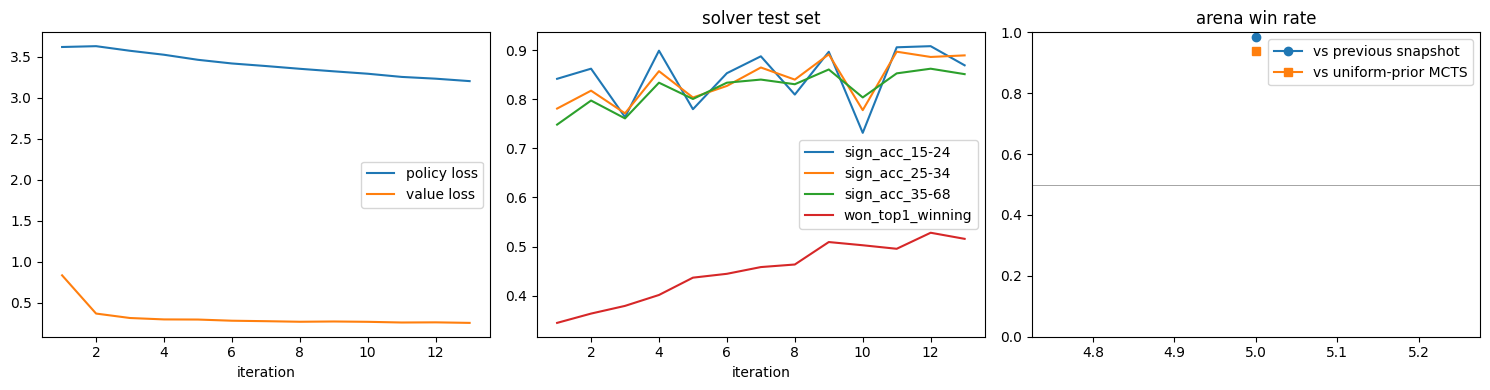

In [ ]:
import matplotlib.pyplot as plt
h1 = [h for h in history if h["phase"] == 1]
log(f"plotting {len(h1)} self-play iterations")
if h1:
    it = [h["iter"] for h in h1]
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].plot(it, [h["policy"] for h in h1], label="policy loss")
    ax[0].plot(it, [h["value"] for h in h1], label="value loss"); ax[0].legend(); ax[0].set_xlabel("iteration")
    for k in [k for k in h1[-1] if k.startswith("sign_acc_")] + ["won_top1_winning"]:
        ax[1].plot(it, [h.get(k, np.nan) for h in h1], label=k)
    ax[1].legend(); ax[1].set_title("solver test set"); ax[1].set_xlabel("iteration")
    ar = [h for h in h1 if "arena_vs_prev" in h]
    ax[2].plot([h["iter"] for h in ar], [h["arena_vs_prev"] for h in ar], "o-", label="vs previous snapshot")
    ax[2].plot([h["iter"] for h in ar], [h["arena_vs_uniform"] for h in ar], "s-", label="vs uniform-prior MCTS")
    ax[2].axhline(0.5, color="grey", lw=0.5); ax[2].set_ylim(0, 1); ax[2].legend(); ax[2].set_title("arena win rate")
    plt.tight_layout(); plt.show()

## 10. Look at a position
The network's value and top moves for a test position, next to the solver's verdict.

In [ ]:
i = int(np.argmax(test_blocks >= 25))
x, legal, _ = S.encode(test_states[i:i+1], np.zeros(1, np.int32))
logits, v = predict(variables_of(state), x)
p = np.exp(np.where(legal[0], logits[0, :S.NMOVE], -1e9)); p /= p.sum()
dirs = ["NW", "N", "NE", "W", "E", "SW", "S", "SE"]
print(S.pretty(test_states[i]))
print(f"solver: {'WIN' if test_v[i] == 1 else 'LOSS'} for X | network value {v[0]:+.2f}")
for a in np.argsort(-p)[:5]:
    k, dm, db = a // 64, (a // 8) % 8, a % 8
    tag = "proven win" if test_win[i, a] else ""
    print(f"  worker {k} move {dirs[dm]:>2} build {dirs[db]:>2}   p={p[a]:.3f}  {tag}")

    A  B  C  D  E
 1  1  3  1  1  0O
 2  1  1  1  2  2 
 3  1  1  2X 0  1 
 4  1X 1  [] 1  0O
 5  0  1  0  2  1 
(X = to move, O = opponent, [] = dome)
solver: WIN for X | network value +0.91
  worker 1 move NE build  N   p=0.058  proven win
  worker 0 move  E build NE   p=0.051  
  worker 1 move NE build SW   p=0.049  
  worker 1 move NE build NW   p=0.043  proven win
  worker 1 move NE build NE   p=0.041  proven win
